In [1]:
# feature engineering, preprocessing and model pipeline (formerly crime_pipeline.py)
import re
from collections import Counter

import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

SEED = 42
FMT = '%m/%d/%Y %I:%M:%S %p'

NUM_COLS = ['Latitude', 'Longitude', 'Victim_Age', 'hour', 'month', 'dow_num', 'report_lag_log',
            'n_mo_codes', 'premise_freq', 'district_freq']
BIN_BASE = ['is_weekend', 'hour_sin', 'hour_cos', 'part2', 'has_weapon', 'has_victim',
            'has_cross_street', 'age_missing', 'geo_missing']
CAT_COLS = ['Area_Name', 'Victim_Sex', 'Victim_Descent', 'Status_Description',
            'weapon_group', 'time_of_day', 'premise_range']
WINSOR_COLS = ['Victim_Age', 'report_lag_days', 'n_mo_codes', 'Latitude', 'Longitude']


def weapon_group(w):
    if pd.isna(w):
        return 'None recorded'
    w = str(w).upper()
    if 'STRONG-ARM' in w or 'PHYSICAL PRESENCE' in w:
        return 'Bodily force'
    if 'VERBAL' in w or 'DEMAND NOTE' in w or 'BOMB THREAT' in w:
        return 'Verbal threat'
    if re.search(r'SIMULATED GUN|TOY GUN|AIR PISTOL|STUN GUN|STARTER PISTOL', w):
        return 'Imitation or non-lethal'
    if re.search(r'GUN|PISTOL|REVOLVER|RIFLE|FIREARM|SHOTGUN|ASSAULT', w):
        return 'Firearm'
    if re.search(r'KNIFE|BLADE|CUTTING|MACHETE|AXE|SCISSORS|CLEAVER|SCREWDRIVER|ICE PICK', w):
        return 'Blade or sharp object'
    if re.search(r'CLUB|BAT|PIPE|STICK|HAMMER|BLUNT|BOARD|TIRE IRON|BRASS|CONCRETE|ROCK|BOTTLE|GLASS|BELT|FIXED OBJECT', w):
        return 'Blunt or thrown object'
    return 'Other'


class CrimeFeatureBuilder(BaseEstimator, TransformerMixin):
    """Raw incident rows in, model-ready feature table out.

    Handles missing values and outliers. Everything that is learned from data
    (medians, frequencies, MO codes, winsorising bounds) is learned in fit only.
    """

    def __init__(self, winsorize=True, lower_q=0.01, upper_q=0.99, n_mo=30, drop_status=False):
        self.winsorize = winsorize
        self.lower_q = lower_q
        self.upper_q = upper_q
        self.n_mo = n_mo
        self.drop_status = drop_status

    def _base(self, X):
        d = pd.DataFrame(index=X.index)
        occ = pd.to_datetime(X['Date_Occurred'], format=FMT, errors='coerce')
        rep = pd.to_datetime(X['Date_Reported'], format=FMT, errors='coerce')
        lat = pd.to_numeric(X['Latitude'], errors='coerce')
        lon = pd.to_numeric(X['Longitude'], errors='coerce')
        bad_geo = lat.isna() | lon.isna() | (lat == 0) | (lon == 0)
        d['geo_missing'] = bad_geo.astype(int)
        d['Latitude'] = lat.where(~bad_geo)
        d['Longitude'] = lon.where(~bad_geo)
        age = pd.to_numeric(X['Victim_Age'], errors='coerce')
        d['age_missing'] = (age.isna() | (age <= 0)).astype(int)
        d['Victim_Age'] = age.where(age > 0)
        t = pd.to_numeric(X['Time_Occurred'], errors='coerce')
        d['hour'] = (t // 100).where((t >= 0) & (t <= 2359))
        d['month'] = occ.dt.month
        d['dow_num'] = occ.dt.dayofweek
        d['report_lag_days'] = (rep - occ).dt.days.clip(lower=0)
        d['n_mo_codes'] = X['Modus_Operandi'].fillna('').astype(str).str.split().str.len()
        d['part2'] = (X['Part 1-2'] == 2).astype(int)
        d['has_weapon'] = X['Weapon_Description'].notna().astype(int)
        d['has_victim'] = X['Victim_Sex'].notna().astype(int)
        d['has_cross_street'] = X['Cross_Street'].notna().astype(int)
        d['Area_Name'] = X['Area_Name'].fillna('Unknown')
        d['Victim_Sex'] = X['Victim_Sex'].replace({'H': 'Unknown'}).fillna('Unknown')
        d['Victim_Descent'] = X['Victim_Descent'].fillna('Unknown')
        d['Status_Description'] = X['Status_Description'].fillna('Unknown')
        d['weapon_group'] = X['Weapon_Description'].apply(weapon_group)
        d['premise_range'] = (pd.to_numeric(X['Premise_Code'], errors='coerce') // 100).astype('Int64').astype(str)
        d['Premise_Description'] = X['Premise_Description'].fillna('UNKNOWN')
        d['Reporting_District_no'] = X['Reporting_District_no']
        d['MO'] = X['Modus_Operandi'].fillna('').astype(str)
        return d

    def _impute(self, d):
        d = d.copy()
        for c in ['Latitude', 'Longitude']:
            d[c] = d[c].fillna(d['Area_Name'].map(self.geo_med_[c])).fillna(self.geo_global_[c])
        d['Victim_Age'] = d['Victim_Age'].fillna(self.age_median_)
        d['hour'] = d['hour'].fillna(self.hour_median_)
        d['month'] = d['month'].fillna(self.month_median_)
        d['dow_num'] = d['dow_num'].fillna(self.dow_median_)
        d['report_lag_days'] = d['report_lag_days'].fillna(self.lag_median_)
        return d

    def fit(self, X, y=None):
        d = self._base(X)
        self.age_median_ = d['Victim_Age'].median()
        self.hour_median_ = d['hour'].median()
        self.month_median_ = d['month'].median()
        self.dow_median_ = d['dow_num'].median()
        self.lag_median_ = d['report_lag_days'].median()
        self.geo_med_ = d.groupby('Area_Name')[['Latitude', 'Longitude']].median()
        self.geo_global_ = d[['Latitude', 'Longitude']].median()
        self.prem_freq_ = d['Premise_Description'].value_counts(normalize=True)
        self.dist_freq_ = d['Reporting_District_no'].value_counts(normalize=True)
        counts = Counter(code for s in d['MO'] for code in s.split())
        self.mo_codes_ = [c for c, _ in counts.most_common(self.n_mo)]
        d = self._impute(d)
        self.bounds_ = {}
        if self.winsorize:
            for c in WINSOR_COLS:
                self.bounds_[c] = (d[c].quantile(self.lower_q), d[c].quantile(self.upper_q))
        return self

    def transform(self, X):
        d = self._impute(self._base(X))
        for c, (lo, hi) in self.bounds_.items():
            d[c] = d[c].clip(lo, hi)
        d['report_lag_log'] = np.log1p(d['report_lag_days'].clip(upper=365))
        d['is_weekend'] = (d['dow_num'] >= 5).astype(int)
        d['hour_sin'] = np.sin(2 * np.pi * d['hour'] / 24)
        d['hour_cos'] = np.cos(2 * np.pi * d['hour'] / 24)
        d['time_of_day'] = pd.cut(d['hour'], [-1, 5, 11, 17, 24],
                                  labels=['late_night', 'morning', 'afternoon', 'evening']).astype(object)
        d['premise_freq'] = d['Premise_Description'].map(self.prem_freq_).fillna(0)
        d['district_freq'] = d['Reporting_District_no'].map(self.dist_freq_).fillna(0)
        sets = d['MO'].str.split().apply(set)
        mo = pd.DataFrame({f'mo_{c}': sets.apply(lambda s, c=c: int(c in s)) for c in self.mo_codes_}, index=d.index)
        cat = [c for c in CAT_COLS if not (self.drop_status and c == 'Status_Description')]
        return pd.concat([d[NUM_COLS + BIN_BASE + cat], mo], axis=1)


def num_selector(df):
    return [c for c in NUM_COLS if c in df.columns]


def bin_selector(df):
    return [c for c in df.columns if c in BIN_BASE or c.startswith('mo_')]


def cat_selector(df):
    return [c for c in CAT_COLS if c in df.columns]


class CorrelationFilter(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.95):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        c = np.nan_to_num(np.abs(np.corrcoef(X, rowvar=False)))
        self.keep_ = ~(np.triu(c, 1) > self.threshold).any(axis=0)
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_]


class WeightedXGB(XGBClassifier):
    """XGBoost with balanced sample weights computed inside fit."""

    def fit(self, X, y, **kw):
        return super().fit(X, y, sample_weight=compute_sample_weight('balanced', y), **kw)


def smote_strategy(target=1000):
    def f(y):
        return {k: target for k, n in Counter(y).items() if n < target}
    return f


def make_model(name, strategy='none', seed=SEED):
    cw = 'balanced' if strategy == 'class_weight' else None
    if name == 'LogReg':
        return LogisticRegression(max_iter=300, C=1.0, class_weight=cw, random_state=seed)
    if name == 'RandomForest':
        return RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight=cw, n_jobs=1, random_state=seed)
    if name == 'ExtraTrees':
        return ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2, class_weight=cw, n_jobs=1, random_state=seed)
    if name == 'HistGB':
        return HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1, class_weight=cw, random_state=seed)
    if name == 'XGBoost':
        cls = WeightedXGB if strategy == 'class_weight' else XGBClassifier
        return cls(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                   tree_method='hist', n_jobs=1, random_state=seed, eval_metric='mlogloss')
    raise ValueError(name)


def build_pipeline(name, strategy='none', winsorize=True, drop_status=False, seed=SEED, estimator=None):
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_selector),
        ('bin', SimpleImputer(strategy='constant', fill_value=0), bin_selector),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Unknown')),
                          ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30,
                                               sparse_output=False))]), cat_selector),
    ], remainder='drop', verbose_feature_names_out=True)
    sampler = SMOTE(sampling_strategy=smote_strategy(), k_neighbors=5, random_state=seed) \
        if strategy == 'smote' else 'passthrough'
    clf = estimator if estimator is not None else make_model(name, strategy, seed)
    return ImbPipeline([
        ('features', CrimeFeatureBuilder(winsorize=winsorize, drop_status=drop_status)),
        ('prep', prep),
        ('var', VarianceThreshold(threshold=0.004)),
        ('corr', CorrelationFilter(0.95)),
        ('sampler', sampler),
        ('clf', clf),
    ])


def feature_names(pipe):
    names = pipe.named_steps['prep'].get_feature_names_out()
    names = names[pipe.named_steps['var'].get_support()]
    names = names[pipe.named_steps['corr'].keep_]
    return [n.split('__', 1)[1] for n in names]


PARAM_SPACES = {
    'LogReg': {'clf__C': [0.01, 0.1, 1, 10, 100]},
    'RandomForest': {'clf__n_estimators': [200, 300, 400], 'clf__max_depth': [None, 12, 20, 30],
                     'clf__min_samples_leaf': [1, 2, 4], 'clf__max_features': ['sqrt', 'log2', 0.3]},
    'ExtraTrees': {'clf__n_estimators': [200, 300, 400], 'clf__max_depth': [None, 12, 20, 30],
                   'clf__min_samples_leaf': [1, 2, 4], 'clf__max_features': ['sqrt', 'log2', 0.3]},
    'HistGB': {'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__max_iter': [100, 150, 250],
               'clf__max_leaf_nodes': [15, 31, 63], 'clf__min_samples_leaf': [10, 20, 40],
               'clf__l2_regularization': [0.0, 0.1, 1.0]},
    'XGBoost': {'clf__n_estimators': [150, 250, 350], 'clf__max_depth': [4, 6, 8],
                'clf__learning_rate': [0.03, 0.05, 0.1], 'clf__subsample': [0.7, 0.85, 1.0],
                'clf__colsample_bytree': [0.6, 0.8, 1.0], 'clf__min_child_weight': [1, 3, 5]},
}


In [2]:
# imports and settings
import os, json, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score)
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance

import sys
cp = sys.modules[__name__]  # pipeline code is defined in the first cell of this notebook

warnings.filterwarnings('ignore')
os.makedirs('figures_model', exist_ok=True)
os.makedirs('model', exist_ok=True)
SEED = 42
N_ITER = 20
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'axes.titlesize': 12, 'axes.labelsize': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

def show(name):
    plt.tight_layout()
    plt.savefig(f'figures_model/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

In [3]:
# load, remove duplicates, stratified split (same split as the preprocessing notebook)
df = pd.read_csv('train.csv')
print('raw shape:', df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print('after removing duplicates:', df.shape)

le = LabelEncoder().fit(df.Crime_Category)
classes = list(le.classes_)
y = pd.Series(le.transform(df.Crime_Category), index=df.index, name='target')
X = df.drop(columns='Crime_Category')

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print('train:', Xtr.shape, 'test:', Xte.shape)
pd.DataFrame({'class': classes,
              'train': np.bincount(ytr), 'test': np.bincount(yte),
              'train_pct': (np.bincount(ytr) / len(ytr) * 100).round(2)})

raw shape: (20000, 22)
after removing duplicates: (19987, 22)
train: (15989, 21) test: (3998, 21)


,class,train,test,train_pct
0,Crimes against Persons,180,45,1.13
1,Crimes against Public Order,1446,362,9.04
2,Fraud and White-Collar Crimes,1083,271,6.77
3,Other Crimes,143,36,0.89
4,Property Crimes,9327,2332,58.33
5,Violent Crimes,3810,952,23.83


In [4]:
# missing value handling: what is missing and what the pipeline does with it
rows = [
    ['Cross_Street', int(Xtr.Cross_Street.isna().sum()), 'not an error, only filled for intersections', 'flag has_cross_street, raw column not used'],
    ['Weapon_Description', int(Xtr.Weapon_Description.isna().sum()), 'blank means no weapon recorded', 'flag has_weapon, group set to None recorded'],
    ['Modus_Operandi', int(Xtr.Modus_Operandi.isna().sum()), 'MO not recorded', 'number of codes = 0, code flags = 0'],
    ['Victim_Sex / Victim_Descent', int(Xtr.Victim_Sex.isna().sum()), 'no individual victim (age is 0 too)', 'category Unknown, flag has_victim'],
    ['Victim_Sex = H', int((Xtr.Victim_Sex == 'H').sum()), 'invalid code', 'recoded to Unknown'],
    ['Victim_Age <= 0', int((Xtr.Victim_Age <= 0).sum()), 'placeholder for unknown', 'set to missing, median of train, flag age_missing'],
    ['Latitude / Longitude = 0', int(((Xtr.Latitude == 0) | (Xtr.Longitude == 0)).sum()), 'location not recorded', 'set to missing, median of the same area, flag geo_missing'],
    ['Premise_Description', int(Xtr.Premise_Description.isna().sum()), 'data entry gap', 'category UNKNOWN'],
]
pd.DataFrame(rows, columns=['column', 'rows_in_train', 'meaning', 'treatment in pipeline'])

,column,rows_in_train,meaning,treatment in pipeline
0,Cross_Street,13224,"not an error, only filled for intersections","flag has_cross_street, raw column not used"
1,Weapon_Description,10135,blank means no weapon recorded,"flag has_weapon, group set to None recorded"
2,Modus_Operandi,2195,MO not recorded,"number of codes = 0, code flags = 0"
3,Victim_Sex / Victim_Descent,2107,no individual victim (age is 0 too),"category Unknown, flag has_victim"
4,Victim_Sex = H,2,invalid code,recoded to Unknown
5,Victim_Age <= 0,3863,placeholder for unknown,"set to missing, median of train, flag age_missing"
6,Latitude / Longitude = 0,61,location not recorded,"set to missing, median of the same area, flag ..."
7,Premise_Description,3,data entry gap,category UNKNOWN


In [5]:
# check: no missing values are left after the feature builder
fb = cp.CrimeFeatureBuilder().fit(Xtr)
F = fb.transform(Xtr)
print('feature table:', F.shape)
print('missing values left:', int(F.isna().sum().sum()))
F.head()

feature table: (15989, 56)
missing values left: 0


,Latitude,Longitude,Victim_Age,hour,month,dow_num,report_lag_log,n_mo_codes,premise_freq,district_freq,is_weekend,hour_sin,hour_cos,part2,has_weapon,has_victim,has_cross_street,age_missing,geo_missing,Area_Name,Victim_Sex,Victim_Descent,Status_Description,weapon_group,time_of_day,premise_range,mo_1822,mo_0344,mo_0913,mo_0329,mo_0416,mo_1300,mo_2000,mo_0400,mo_1402,mo_2004,mo_1814,mo_1202,mo_1309,mo_0444,mo_0334,mo_1609,mo_0325,mo_1307,mo_0421,mo_0446,mo_0342,mo_1501,mo_1606,mo_1813,mo_1218,mo_0432,mo_0448,mo_0429,mo_0906,mo_1607
3598,33.9882,-118.4699,51.0,3.0,11,2,1.098612,2,0.251923,0.003377,0,7.071068e-01,0.707107,0,0,1,0,0,0,Pacific,F,O,Invest Cont,None recorded,late_night,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
19085,33.7958,-118.2937,45.0,12.0,6,4,2.197225,4,0.126712,0.000938,0,1.224647e-16,-1.000000,1,1,1,0,0,0,Harbor,F,B,Invest Cont,Bodily force,afternoon,5,0,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0
8245,34.1985,-118.4749,37.0,20.0,4,6,0.000000,6,0.251923,0.000938,1,-8.660254e-01,0.500000,1,1,1,0,1,0,West Valley,M,O,Invest Cont,Firearm,evening,1,1,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4735,34.0707,-118.2143,34.0,10.0,11,6,0.000000,6,0.167490,0.001126,1,5.000000e-01,-0.866025,0,1,1,0,0,0,Hollenbeck,M,H,Invest Cont,Firearm,morning,5,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
16535,34.2537,-118.5886,39.0,20.0,2,5,0.000000,5,0.126712,0.000688,1,-8.660254e-01,0.500000,1,1,1,0,0,0,Devonshire,F,B,Adult Other,Bodily force,evening,5,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


In [6]:
# outlier detection on the engineered continuous features (train split)
fb0 = cp.CrimeFeatureBuilder(winsorize=False).fit(Xtr)
d_raw = fb0._impute(fb0._base(Xtr))
fb1 = cp.CrimeFeatureBuilder(winsorize=True, lower_q=0.01, upper_q=0.99).fit(Xtr)
d_win = d_raw.copy()
for col, (lo, hi) in fb1.bounds_.items():
    d_win[col] = d_win[col].clip(lo, hi)

rows = []
for col in cp.WINSOR_COLS:
    s = d_raw[col]
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo_f, hi_f = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    lo_w, hi_w = fb1.bounds_[col]
    rows.append([col, s.min(), s.max(), int(((s < lo_f) | (s > hi_f)).sum()),
                 round(lo_w, 3), round(hi_w, 3), int(((s < lo_w) | (s > hi_w)).sum()),
                 d_win[col].min(), d_win[col].max()])
outlier_table = pd.DataFrame(rows, columns=['feature', 'min', 'max', 'iqr_outliers', 'clip_low', 'clip_high',
                                            'rows_clipped', 'min_after', 'max_after'])
outlier_table

,feature,min,max,iqr_outliers,clip_low,clip_high,rows_clipped,min_after,max_after
0,Victim_Age,2.0000,99.0000,501,13.000,78.000,309,13.000000,78.000000
1,report_lag_days,0.0000,1437.0000,2440,0.000,731.000,159,0.000000,731.000000
2,n_mo_codes,0.0000,10.0000,481,0.000,10.000,0,0.000000,10.000000
3,Latitude,33.7070,34.3281,377,33.735,34.303,312,33.734700,34.302772
4,Longitude,-118.6634,-118.1602,1,-118.614,-118.192,320,-118.613512,-118.191576


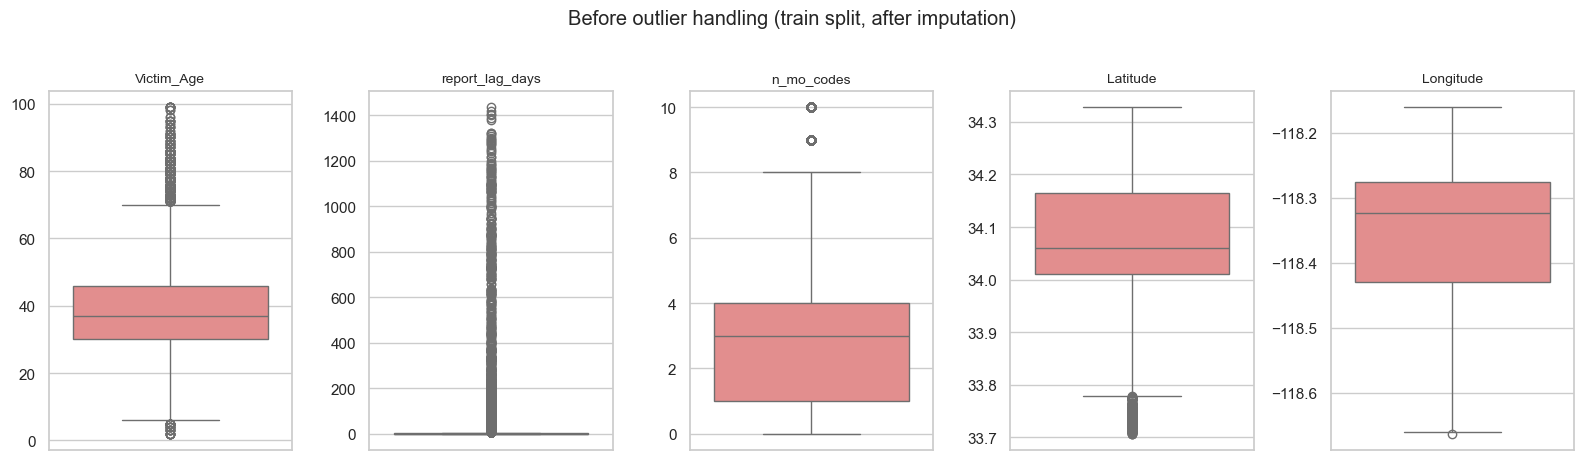

In [7]:
# figure 1: continuous features before outlier handling
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))
for ax, col in zip(axes, cp.WINSOR_COLS):
    sns.boxplot(y=d_raw[col], ax=ax, color='lightcoral')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
fig.suptitle('Before outlier handling (train split, after imputation)', y=1.02)
show('m01_outliers_before')

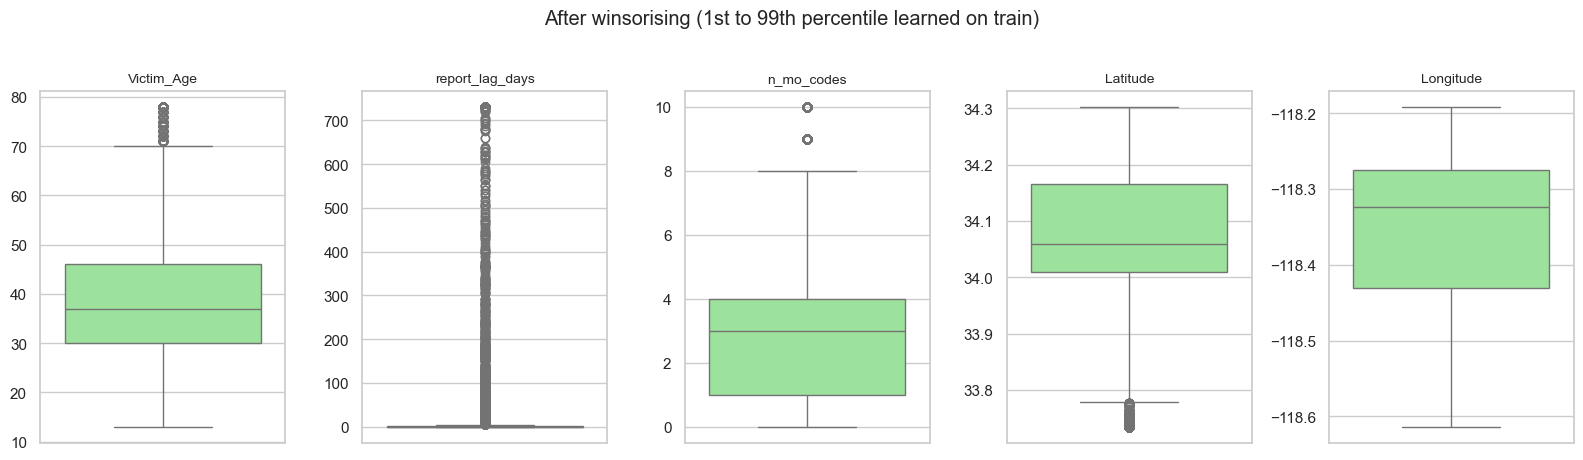

In [8]:
# figure 2: continuous features after winsorising at the 1st and 99th percentile
fig, axes = plt.subplots(1, 5, figsize=(16, 4.5))
for ax, col in zip(axes, cp.WINSOR_COLS):
    sns.boxplot(y=d_win[col], ax=ax, color='lightgreen')
    ax.set_title(col, fontsize=10)
    ax.set_ylabel('')
fig.suptitle('After winsorising (1st to 99th percentile learned on train)', y=1.02)
show('m02_outliers_after')

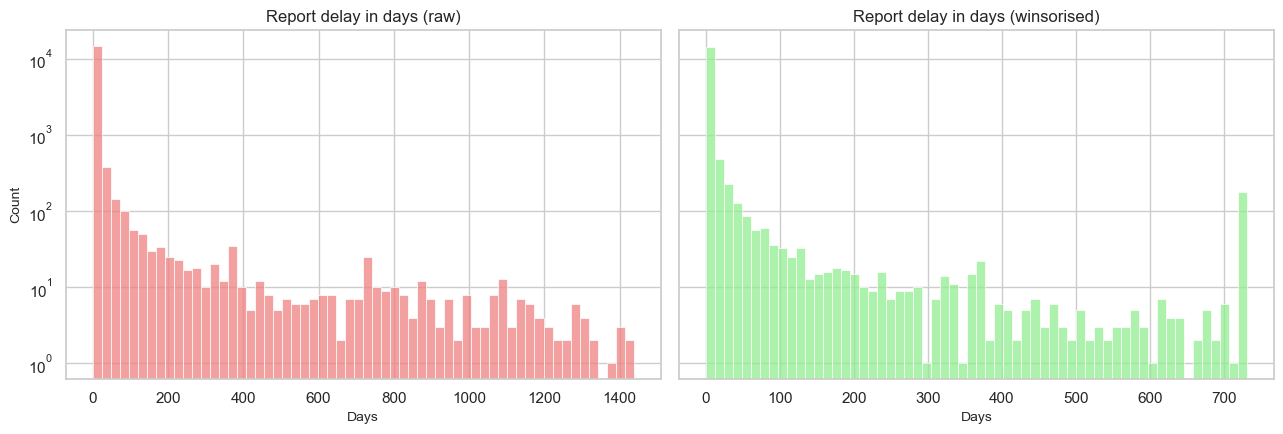

In [9]:
# figure 3: reporting delay before and after capping
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
sns.histplot(d_raw.report_lag_days, bins=60, ax=axes[0], color='lightcoral')
axes[0].set_title('Report delay in days (raw)')
axes[0].set_xlabel('Days')
axes[0].set_yscale('log')
sns.histplot(d_win.report_lag_days, bins=60, ax=axes[1], color='lightgreen')
axes[1].set_title('Report delay in days (winsorised)')
axes[1].set_xlabel('Days')
axes[1].set_yscale('log')
show('m03_report_lag_capped')

In [10]:
# does outlier handling change model performance? 5-fold CV on the train split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name in ['LogReg', 'RandomForest', 'XGBoost']:
    for w in [False, True]:
        r = cross_validate(cp.build_pipeline(name, 'class_weight', winsorize=w), Xtr, ytr, cv=skf,
                           scoring='f1_macro', n_jobs=1)
        rows.append([name, 'winsorised' if w else 'not winsorised', r['test_score'].mean(), r['test_score'].std()])
        print(rows[-1])
outlier_ablation = pd.DataFrame(rows, columns=['model', 'outliers', 'cv_macro_f1', 'std'])
outlier_ablation.round(4)

['LogReg', 'not winsorised', np.float64(0.6633666925912489), np.float64(0.005894949646538424)]
['LogReg', 'winsorised', np.float64(0.660935406757153), np.float64(0.004034508374141566)]
['RandomForest', 'not winsorised', np.float64(0.7515306369283052), np.float64(0.014503731612486416)]
['RandomForest', 'winsorised', np.float64(0.7472285766554443), np.float64(0.011748901457669662)]
['XGBoost', 'not winsorised', np.float64(0.7648964482414169), np.float64(0.005100346991502231)]
['XGBoost', 'winsorised', np.float64(0.7651300605732726), np.float64(0.0076805970192963995)]


,model,outliers,cv_macro_f1,std
0,LogReg,not winsorised,0.6634,0.0059
1,LogReg,winsorised,0.6609,0.0040
2,RandomForest,not winsorised,0.7515,0.0145
3,RandomForest,winsorised,0.7472,0.0117
4,XGBoost,not winsorised,0.7649,0.0051
5,XGBoost,winsorised,0.7651,0.0077


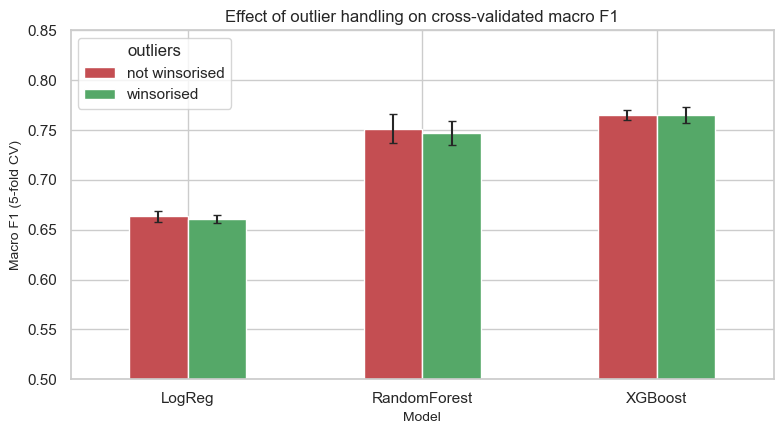

In [11]:
# figure 4: macro F1 with and without winsorising
piv = outlier_ablation.pivot(index='model', columns='outliers', values='cv_macro_f1')
errs = outlier_ablation.pivot(index='model', columns='outliers', values='std')
piv.plot(kind='bar', yerr=errs, figsize=(8, 4.5), capsize=3, color=['#c44e52', '#55a868'])
plt.title('Effect of outlier handling on cross-validated macro F1')
plt.xlabel('Model')
plt.ylabel('Macro F1 (5-fold CV)')
plt.xticks(rotation=0)
plt.ylim(0.5, 0.85)
show('m04_outlier_ablation')

In [12]:
# imbalance: class counts and what SMOTE does inside the pipeline
pipe_s = cp.build_pipeline('RandomForest', 'smote')
pre = pipe_s[:4]
Xt = pre.fit_transform(Xtr, ytr)
Xs, ys = pipe_s.named_steps['sampler'].fit_resample(Xt, ytr)
imb = pd.DataFrame({'class': classes, 'original': np.bincount(ytr), 'after_smote': np.bincount(ys)})
imb['class_weight_balanced'] = (len(ytr) / (len(classes) * imb.original)).round(3)
print('features after preprocessing:', Xt.shape[1])
imb

features after preprocessing: 101


,class,original,after_smote,class_weight_balanced
0,Crimes against Persons,180,1000,14.805
1,Crimes against Public Order,1446,1446,1.843
2,Fraud and White-Collar Crimes,1083,1083,2.461
3,Other Crimes,143,1000,18.635
4,Property Crimes,9327,9327,0.286
5,Violent Crimes,3810,3810,0.699


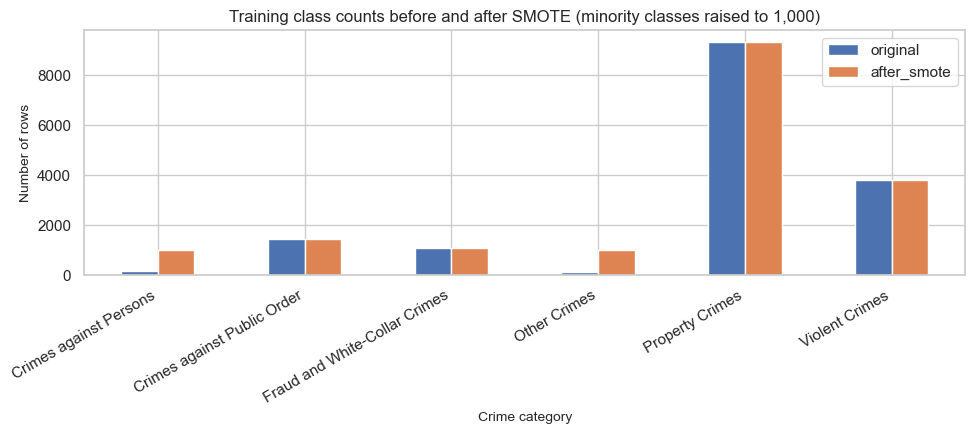

In [13]:
# figure 5: class counts before and after SMOTE (training data only)
imb.set_index('class')[['original', 'after_smote']].plot(kind='bar', figsize=(10, 4.5), color=['#4c72b0', '#dd8452'])
plt.title('Training class counts before and after SMOTE (minority classes raised to 1,000)')
plt.xlabel('Crime category')
plt.ylabel('Number of rows')
plt.xticks(rotation=30, ha='right')
show('m05_smote_counts')

In [14]:
# the full pipeline, from raw columns to prediction
cp.build_pipeline('XGBoost', 'class_weight')

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,winsorize,True
,lower_q,0.01
,upper_q,0.99
,n_mo,30
,drop_status,False
,transformers,"[('num', ...), ('bin', ...), ...]"
,remainder,'drop'


In [15]:
# model selection: 5 models x 3 imbalance strategies, 5-fold stratified CV on the train split
MODELS = ['LogReg', 'RandomForest', 'ExtraTrees', 'HistGB', 'XGBoost']
STRATS = ['none', 'class_weight', 'smote']
scoring = {'f1_macro': 'f1_macro', 'bal_acc': 'balanced_accuracy', 'acc': 'accuracy', 'f1_weighted': 'f1_weighted'}
rows = []
for name in MODELS:
    for strat in STRATS:
        t = time.time()
        r = cross_validate(cp.build_pipeline(name, strat), Xtr, ytr, cv=skf, scoring=scoring, n_jobs=1)
        rows.append({'model': name, 'imbalance': strat,
                     'macro_f1': r['test_f1_macro'].mean(), 'macro_f1_std': r['test_f1_macro'].std(),
                     'balanced_acc': r['test_bal_acc'].mean(), 'accuracy': r['test_acc'].mean(),
                     'weighted_f1': r['test_f1_weighted'].mean(), 'fit_time_s': r['fit_time'].mean()})
        print(name, strat, round(rows[-1]['macro_f1'], 4), f'{time.time() - t:.0f}s')
selection = pd.DataFrame(rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
selection.to_csv('model/model_selection.csv', index=False)
selection.round(4)

LogReg none 0.7086 7s
LogReg class_weight 0.6609 9s
LogReg smote 0.7069 9s
RandomForest none 0.6684 27s
RandomForest class_weight 0.7472 28s
RandomForest smote 0.7548 35s
ExtraTrees none 0.6509 27s
ExtraTrees class_weight 0.7281 40s
ExtraTrees smote 0.7204 42s
HistGB none 0.7387 18s
HistGB class_weight 0.7607 10s
HistGB smote 0.7507 20s
XGBoost none 0.7305 39s
XGBoost class_weight 0.7651 39s
XGBoost smote 0.7503 75s


,model,imbalance,macro_f1,macro_f1_std,balanced_acc,accuracy,weighted_f1,fit_time_s
0,XGBoost,class_weight,0.7651,0.0077,0.7652,0.9391,0.9386,7.4656
1,HistGB,class_weight,0.7607,0.0106,0.7890,0.9315,0.9328,1.9025
2,RandomForest,smote,0.7548,0.0254,0.7289,0.9376,0.9352,6.7090
3,HistGB,smote,0.7507,0.0166,0.7369,0.9381,0.9365,3.8326
4,XGBoost,smote,0.7503,0.0144,0.7324,0.9400,0.9380,14.7973
5,RandomForest,class_weight,0.7472,0.0117,0.7340,0.9342,0.9322,5.3422
6,HistGB,none,0.7387,0.0146,0.7227,0.9375,0.9353,3.3163
7,XGBoost,none,0.7305,0.0113,0.7144,0.9390,0.9362,7.6110
8,ExtraTrees,class_weight,0.7281,0.0166,0.7115,0.9324,0.9308,7.4711
9,ExtraTrees,smote,0.7204,0.0260,0.6960,0.9366,0.9334,7.9180


In [16]:
# baseline: majority class predictor on the same folds
dummy = cross_validate(DummyClassifier(strategy='most_frequent'), np.zeros((len(ytr), 1)), ytr, cv=skf,
                       scoring=scoring)
pd.Series({'macro_f1': dummy['test_f1_macro'].mean(), 'balanced_acc': dummy['test_bal_acc'].mean(),
           'accuracy': dummy['test_acc'].mean()}).round(4)

macro_f1        0.1228
balanced_acc    0.1667
accuracy        0.5833
dtype: float64

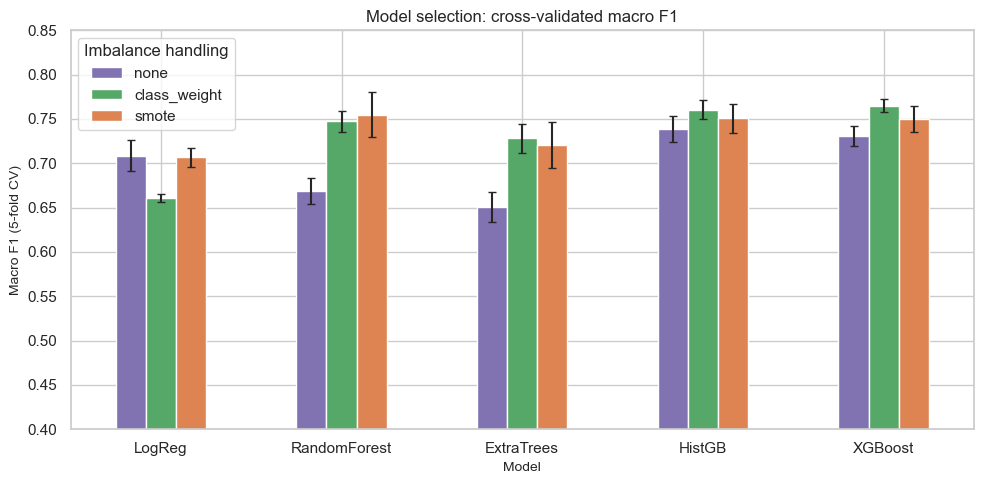

In [17]:
# figure 6: macro F1 by model and imbalance strategy
piv = selection.pivot(index='model', columns='imbalance', values='macro_f1').loc[MODELS, STRATS]
err = selection.pivot(index='model', columns='imbalance', values='macro_f1_std').loc[MODELS, STRATS]
piv.plot(kind='bar', yerr=err, figsize=(10, 5), capsize=3, color=['#8172b2', '#55a868', '#dd8452'])
plt.title('Model selection: cross-validated macro F1')
plt.xlabel('Model')
plt.ylabel('Macro F1 (5-fold CV)')
plt.xticks(rotation=0)
plt.ylim(0.4, 0.85)
plt.legend(title='Imbalance handling')
show('m06_selection_macro_f1')

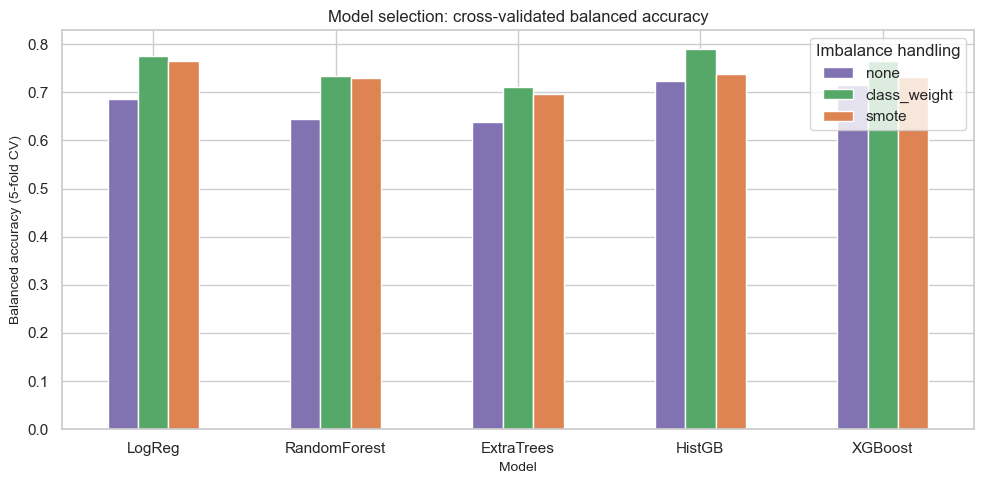

In [18]:
# figure 7: balanced accuracy by model and imbalance strategy
piv = selection.pivot(index='model', columns='imbalance', values='balanced_acc').loc[MODELS, STRATS]
piv.plot(kind='bar', figsize=(10, 5), color=['#8172b2', '#55a868', '#dd8452'])
plt.title('Model selection: cross-validated balanced accuracy')
plt.xlabel('Model')
plt.ylabel('Balanced accuracy (5-fold CV)')
plt.xticks(rotation=0)
plt.legend(title='Imbalance handling')
show('m07_selection_balanced_acc')

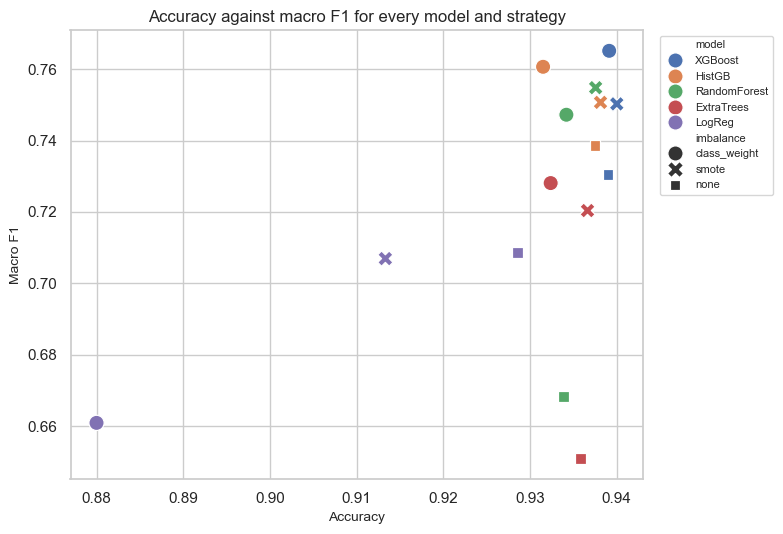

In [19]:
# figure 8: accuracy against macro F1
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=selection, x='accuracy', y='macro_f1', hue='model', style='imbalance', s=120)
plt.title('Accuracy against macro F1 for every model and strategy')
plt.xlabel('Accuracy')
plt.ylabel('Macro F1')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
show('m08_accuracy_vs_f1')

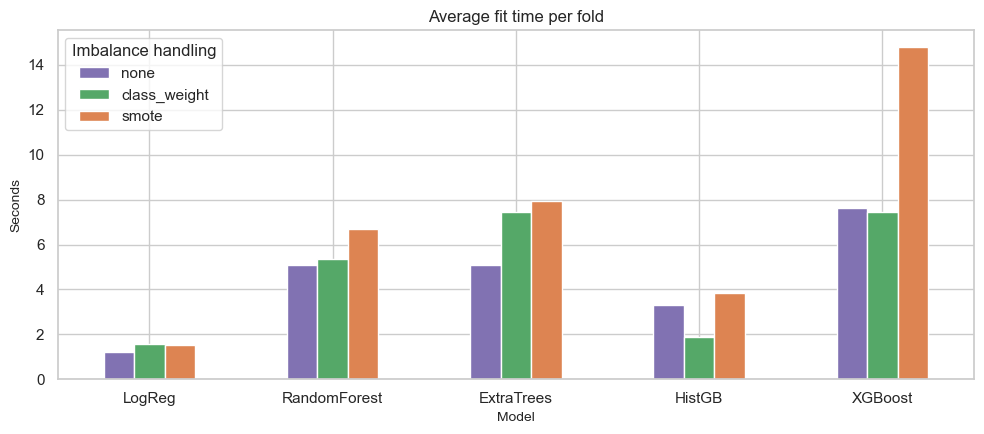

In [20]:
# figure 9: training time per model and strategy
piv = selection.pivot(index='model', columns='imbalance', values='fit_time_s').loc[MODELS, STRATS]
piv.plot(kind='bar', figsize=(10, 4.5), color=['#8172b2', '#55a868', '#dd8452'])
plt.title('Average fit time per fold')
plt.xlabel('Model')
plt.ylabel('Seconds')
plt.xticks(rotation=0)
plt.legend(title='Imbalance handling')
show('m09_fit_time')

In [21]:
# pick the two best models, each with its best imbalance strategy
best_per_model = selection.sort_values('macro_f1', ascending=False).drop_duplicates('model')
top2 = list(zip(best_per_model.model.head(2), best_per_model.imbalance.head(2)))
print('selected for tuning:', top2)
best_per_model[['model', 'imbalance', 'macro_f1', 'balanced_acc', 'accuracy']].round(4)

selected for tuning: [('XGBoost', 'class_weight'), ('HistGB', 'class_weight')]


,model,imbalance,macro_f1,balanced_acc,accuracy
0,XGBoost,class_weight,0.7651,0.7652,0.9391
1,HistGB,class_weight,0.7607,0.7890,0.9315
2,RandomForest,smote,0.7548,0.7289,0.9376
8,ExtraTrees,class_weight,0.7281,0.7115,0.9324
10,LogReg,none,0.7086,0.6859,0.9286


In [22]:
# hyperparameter tuning: randomised search, 5-fold CV, scored on macro F1
searches = {}
for name, strat in top2:
    space = cp.PARAM_SPACES[name]
    size = math.prod(len(v) for v in space.values())
    t = time.time()
    rs = RandomizedSearchCV(cp.build_pipeline(name, strat), space, n_iter=min(N_ITER, size), cv=skf,
                            scoring='f1_macro', random_state=SEED, n_jobs=1, refit=True)
    rs.fit(Xtr, ytr)
    searches[name] = rs
    print(name, strat, 'best CV macro F1:', round(rs.best_score_, 4), f'{time.time() - t:.0f}s')
    print(rs.best_params_)

XGBoost class_weight best CV macro F1: 0.7797 1022s
{'clf__subsample': 1.0, 'clf__n_estimators': 250, 'clf__min_child_weight': 1, 'clf__max_depth': 8, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.8}
HistGB class_weight best CV macro F1: 0.771 319s
{'clf__min_samples_leaf': 10, 'clf__max_leaf_nodes': 31, 'clf__max_iter': 150, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0.0}


In [23]:
# tuning summary: default vs tuned CV score and selected parameters
rows = []
for name, strat in top2:
    default = selection[(selection.model == name) & (selection.imbalance == strat)].macro_f1.iloc[0]
    rows.append([name, strat, round(default, 4), round(searches[name].best_score_, 4),
                 {k.replace('clf__', ''): v for k, v in searches[name].best_params_.items()}])
tuning_summary = pd.DataFrame(rows, columns=['model', 'imbalance', 'cv_f1_default', 'cv_f1_tuned', 'selected_parameters'])
tuning_summary

,model,imbalance,cv_f1_default,cv_f1_tuned,selected_parameters
0,XGBoost,class_weight,0.7651,0.7797,"{'subsample': 1.0, 'n_estimators': 250, 'min_c..."
1,HistGB,class_weight,0.7607,0.7710,"{'min_samples_leaf': 10, 'max_leaf_nodes': 31,..."


In [24]:
# top 10 configurations for each searched model
for name, _ in top2:
    res = pd.DataFrame(searches[name].cv_results_).sort_values('rank_test_score').head(10)
    cols = ['mean_test_score', 'std_test_score', 'mean_fit_time'] + [k for k in res.columns if k.startswith('param_')]
    print(name)
    print(res[cols].round(4).to_string(index=False), '\n')

XGBoost
 mean_test_score  std_test_score  mean_fit_time  param_clf__subsample  param_clf__n_estimators  param_clf__min_child_weight  param_clf__max_depth  param_clf__learning_rate  param_clf__colsample_bytree
          0.7797          0.0075        10.4292                  1.00                      250                            1                     8                      0.03                          0.8
          0.7748          0.0143        18.6470                  0.70                      350                            5                     8                      0.03                          0.6
          0.7745          0.0197        13.9468                  0.70                      350                            1                     6                      0.03                          0.6
          0.7730          0.0158        10.7291                  0.85                      250                            1                     6                      0.05                 

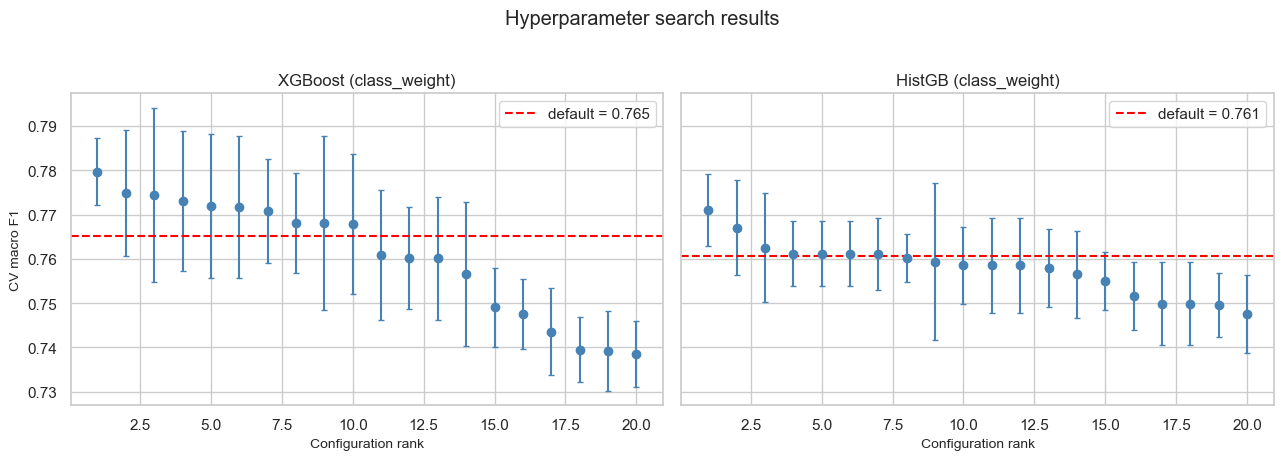

In [25]:
# figure 10: all search results, sorted
fig, axes = plt.subplots(1, len(top2), figsize=(13, 4.5), sharey=True)
for ax, (name, strat) in zip(np.atleast_1d(axes), top2):
    res = pd.DataFrame(searches[name].cv_results_).sort_values('mean_test_score', ascending=False).reset_index(drop=True)
    ax.errorbar(res.index + 1, res.mean_test_score, yerr=res.std_test_score, fmt='o', color='steelblue', capsize=2)
    default = selection[(selection.model == name) & (selection.imbalance == strat)].macro_f1.iloc[0]
    ax.axhline(default, color='red', linestyle='--', label=f'default = {default:.3f}')
    ax.set_title(f'{name} ({strat})')
    ax.set_xlabel('Configuration rank')
    ax.legend()
np.atleast_1d(axes)[0].set_ylabel('CV macro F1')
fig.suptitle('Hyperparameter search results', y=1.02)
show('m10_tuning_results')

In [26]:
# test split evaluation of both tuned models
def evaluate(model):
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)
    return pred, proba, {
        'accuracy': accuracy_score(yte, pred),
        'balanced_acc': balanced_accuracy_score(yte, pred),
        'macro_f1': f1_score(yte, pred, average='macro'),
        'weighted_f1': f1_score(yte, pred, average='weighted'),
        'macro_roc_auc': roc_auc_score(yte, proba, multi_class='ovr', average='macro'),
    }

evals = {}
rows = []
for name, strat in top2:
    pred, proba, m = evaluate(searches[name].best_estimator_)
    evals[name] = (pred, proba)
    rows.append({'model': name, 'imbalance': strat, 'cv_macro_f1': searches[name].best_score_, **m})
dm = DummyClassifier(strategy='most_frequent').fit(Xtr, ytr).predict(Xte)
rows.append({'model': 'Majority baseline', 'imbalance': '-', 'cv_macro_f1': np.nan,
             'accuracy': accuracy_score(yte, dm), 'balanced_acc': balanced_accuracy_score(yte, dm),
             'macro_f1': f1_score(yte, dm, average='macro'), 'weighted_f1': f1_score(yte, dm, average='weighted'),
             'macro_roc_auc': 0.5})
test_results = pd.DataFrame(rows)
test_results.round(4)

,model,imbalance,cv_macro_f1,accuracy,balanced_acc,macro_f1,weighted_f1,macro_roc_auc
0,XGBoost,class_weight,0.7797,0.9337,0.7632,0.7625,0.9340,0.9874
1,HistGB,class_weight,0.7710,0.9312,0.7801,0.7679,0.9321,0.9833
2,Majority baseline,-,NaN,0.5833,0.1667,0.1228,0.4298,0.5000


In [27]:
# the final model is chosen by CV score on the train split, not by the test score
final_name = max(top2, key=lambda t: searches[t[0]].best_score_)[0]
final = searches[final_name].best_estimator_
final_pred, final_proba = evals[final_name]
print('final model:', final_name)
print(classification_report(yte, final_pred, target_names=classes, digits=3))

final model: XGBoost
                               precision    recall  f1-score   support

       Crimes against Persons      0.659     0.644     0.652        45
  Crimes against Public Order      0.777     0.790     0.784       362
Fraud and White-Collar Crimes      0.891     0.900     0.895       271
                 Other Crimes      0.353     0.333     0.343        36
              Property Crimes      0.993     0.973     0.983      2332
               Violent Crimes      0.900     0.938     0.919       952

                     accuracy                          0.934      3998
                    macro avg      0.762     0.763     0.762      3998
                 weighted avg      0.935     0.934     0.934      3998



In [28]:
# per-class metrics
p, r, f, s = precision_recall_fscore_support(yte, final_pred)
per_class = pd.DataFrame({'class': classes, 'precision': p, 'recall': r, 'f1': f, 'support': s})
per_class['roc_auc'] = [roc_auc_score((yte == i).astype(int), final_proba[:, i]) for i in range(len(classes))]
per_class['avg_precision'] = [average_precision_score((yte == i).astype(int), final_proba[:, i]) for i in range(len(classes))]
per_class.round(3)

,class,precision,recall,f1,support,roc_auc,avg_precision
0,Crimes against Persons,0.659,0.644,0.652,45,0.992,0.666
1,Crimes against Public Order,0.777,0.790,0.784,362,0.983,0.864
2,Fraud and White-Collar Crimes,0.891,0.900,0.895,271,0.997,0.961
3,Other Crimes,0.353,0.333,0.343,36,0.961,0.333
4,Property Crimes,0.993,0.973,0.983,2332,0.998,0.999
5,Violent Crimes,0.900,0.938,0.919,952,0.993,0.980


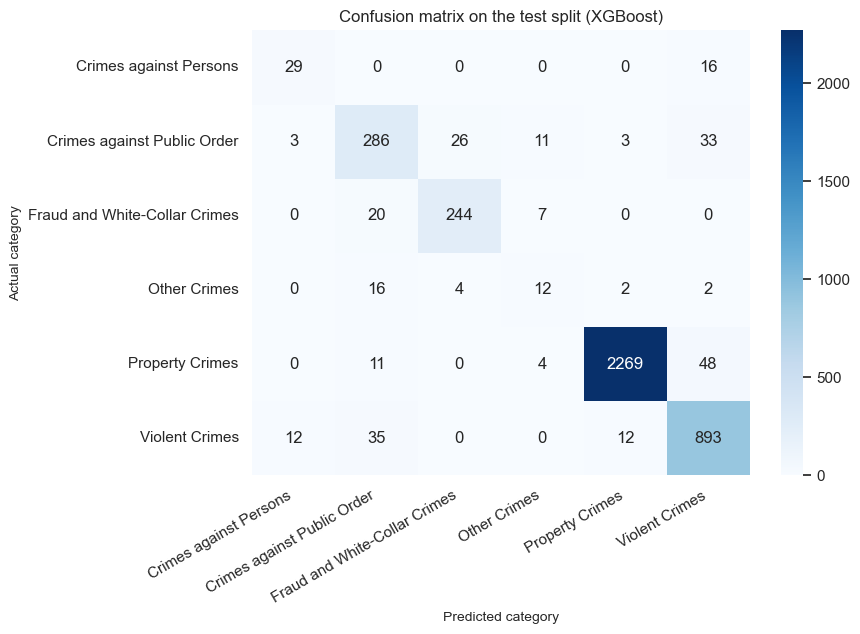

In [29]:
# figure 11: confusion matrix (counts)
cm = confusion_matrix(yte, final_pred)
plt.figure(figsize=(9, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.title(f'Confusion matrix on the test split ({final_name})')
plt.xlabel('Predicted category')
plt.ylabel('Actual category')
plt.xticks(rotation=30, ha='right')
show('m11_confusion_counts')

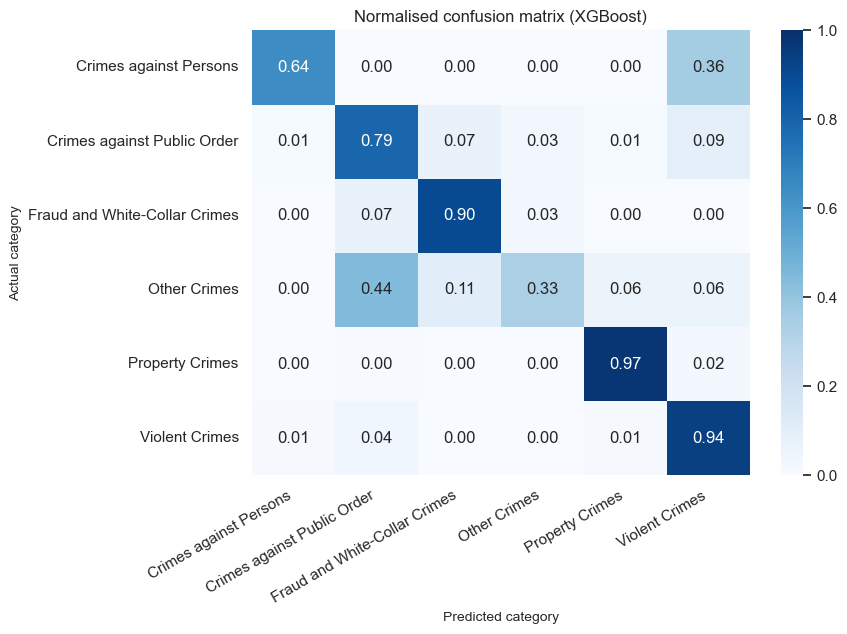

In [30]:
# figure 12: confusion matrix (row percentages, equals recall on the diagonal)
cmn = confusion_matrix(yte, final_pred, normalize='true')
plt.figure(figsize=(9, 6.5))
sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes, vmin=0, vmax=1)
plt.title(f'Normalised confusion matrix ({final_name})')
plt.xlabel('Predicted category')
plt.ylabel('Actual category')
plt.xticks(rotation=30, ha='right')
show('m12_confusion_normalised')

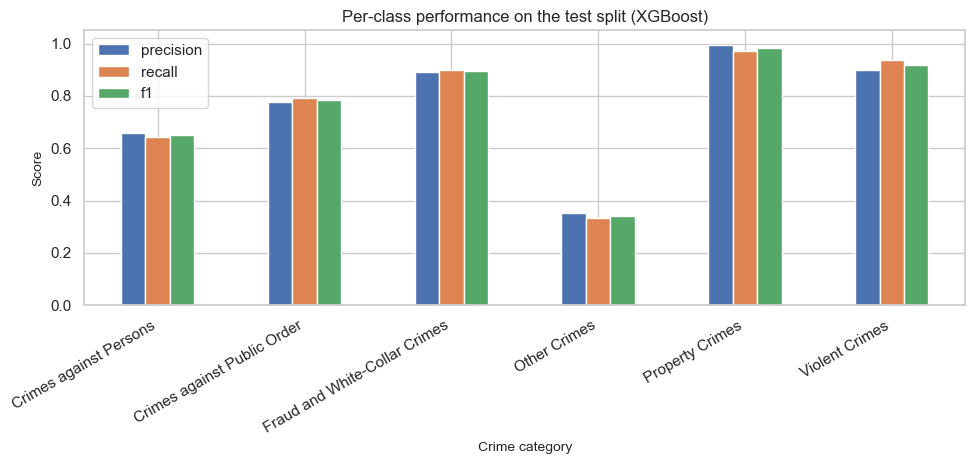

In [31]:
# figure 13: precision, recall and F1 by class
per_class.set_index('class')[['precision', 'recall', 'f1']].plot(kind='bar', figsize=(10, 4.8),
                                                                  color=['#4c72b0', '#dd8452', '#55a868'])
plt.title(f'Per-class performance on the test split ({final_name})')
plt.xlabel('Crime category')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha='right')
show('m13_per_class_scores')

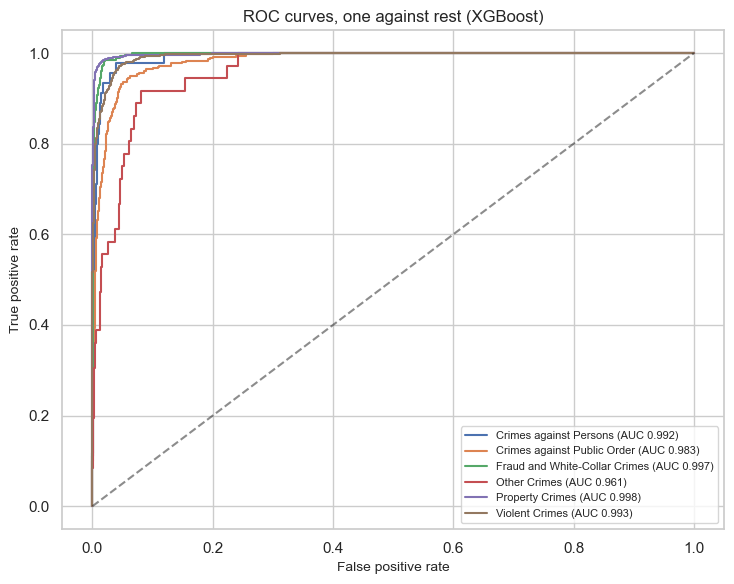

In [32]:
# figure 14: ROC curves, one against rest
Y = label_binarize(yte, classes=range(len(classes)))
plt.figure(figsize=(7.5, 6))
for i, cl in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], final_proba[:, i])
    plt.plot(fpr, tpr, label=f'{cl} (AUC {per_class.roc_auc[i]:.3f})')
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title(f'ROC curves, one against rest ({final_name})')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.legend(fontsize=8, loc='lower right')
show('m14_roc_curves')

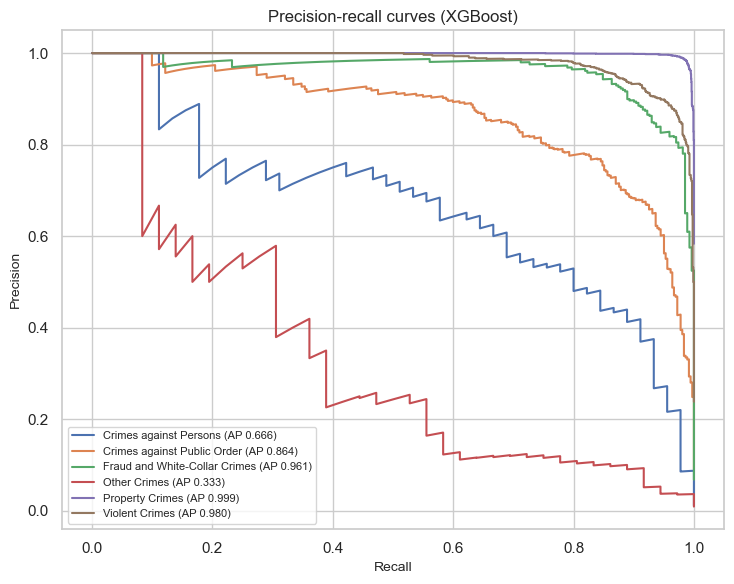

In [33]:
# figure 15: precision-recall curves
plt.figure(figsize=(7.5, 6))
for i, cl in enumerate(classes):
    pr_, rc_, _ = precision_recall_curve(Y[:, i], final_proba[:, i])
    plt.plot(rc_, pr_, label=f'{cl} (AP {per_class.avg_precision[i]:.3f})')
plt.title(f'Precision-recall curves ({final_name})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend(fontsize=8, loc='lower left')
show('m15_pr_curves')

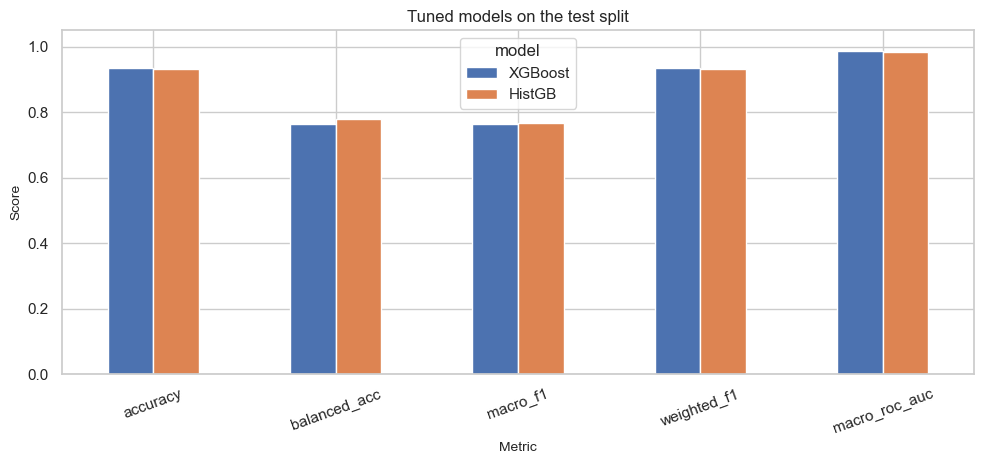

In [34]:
# figure 16: both tuned models compared on the test split
cmp = test_results[test_results.model != 'Majority baseline'].set_index('model')[['accuracy', 'balanced_acc', 'macro_f1', 'weighted_f1', 'macro_roc_auc']]
cmp.T.plot(kind='bar', figsize=(10, 4.8), color=['#4c72b0', '#dd8452'])
plt.title('Tuned models on the test split')
plt.xlabel('Metric')
plt.ylabel('Score')
plt.xticks(rotation=20)
plt.ylim(0, 1.05)
show('m16_model_comparison')

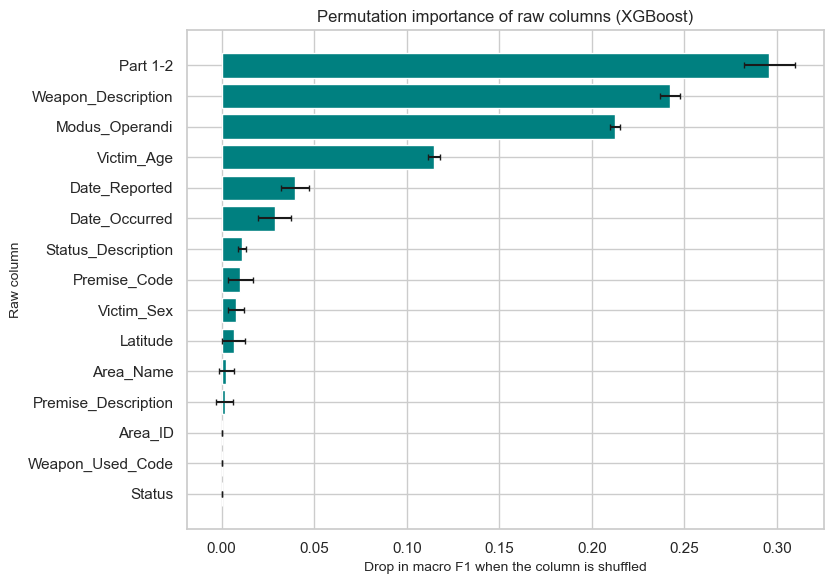

In [35]:
# figure 17: permutation importance of the raw input columns (macro F1 drop on the test split)
pi = permutation_importance(final, Xte, yte, scoring='f1_macro', n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({'column': Xte.columns, 'drop_in_macro_f1': pi.importances_mean, 'std': pi.importances_std})
imp = imp.sort_values('drop_in_macro_f1', ascending=False)
top = imp.head(15).iloc[::-1]
plt.figure(figsize=(8.5, 6))
plt.barh(top.column, top.drop_in_macro_f1, xerr=top['std'], color='teal', capsize=2)
plt.title(f'Permutation importance of raw columns ({final_name})')
plt.xlabel('Drop in macro F1 when the column is shuffled')
plt.ylabel('Raw column')
show('m17_permutation_importance')

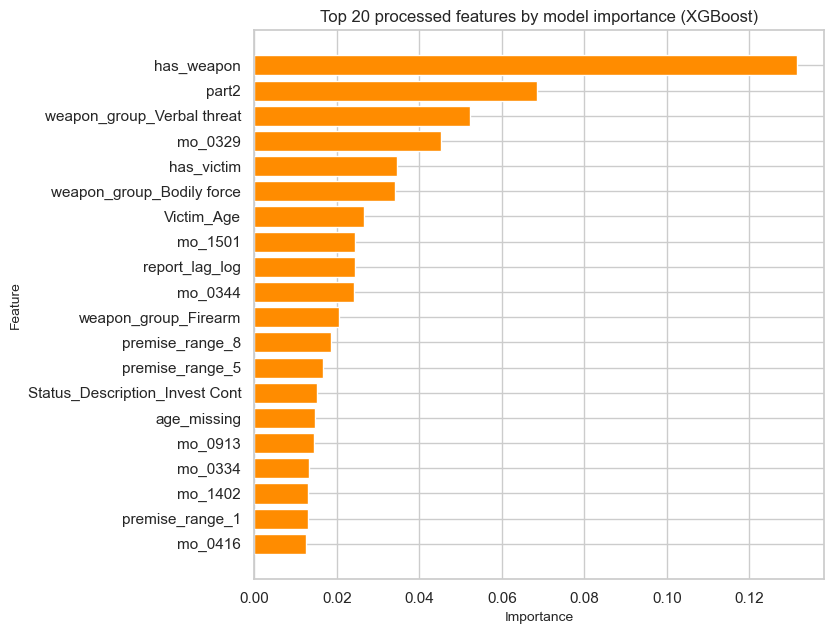

In [36]:
# figure 18: model-internal importance of the processed features (tree models)
clf = final.named_steps['clf']
names = cp.feature_names(final)
if hasattr(clf, 'feature_importances_'):
    fi = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False).head(20).iloc[::-1]
    plt.figure(figsize=(8.5, 6.5))
    plt.barh(fi.index, fi.values, color='darkorange')
    plt.title(f'Top 20 processed features by model importance ({final_name})')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    show('m18_model_importance')
else:
    print('model has no feature_importances_, see permutation importance')

In [37]:
# leakage check: is case status needed? CV macro F1 with and without the status feature
rows = []
for drop in [False, True]:
    est = clone(final).set_params(features__drop_status=drop)
    r = cross_validate(est, Xtr, ytr, cv=skf, scoring='f1_macro', n_jobs=1)
    rows.append(['without status' if drop else 'with status', r['test_score'].mean(), r['test_score'].std()])
status_ablation = pd.DataFrame(rows, columns=['features', 'cv_macro_f1', 'std'])
status_ablation.round(4)

,features,cv_macro_f1,std
0,with status,0.7797,0.0075
1,without status,0.7653,0.0139


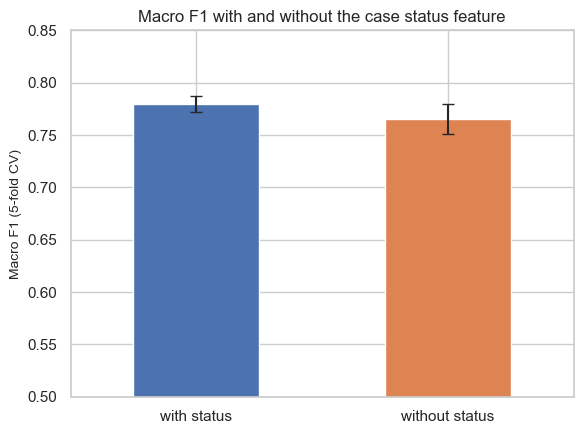

In [38]:
# figure 19: effect of removing the status feature
status_ablation.set_index('features').cv_macro_f1.plot(kind='bar', yerr=status_ablation['std'].values, figsize=(6, 4.5),
                                                       capsize=4, color=['#4c72b0', '#dd8452'])
plt.title('Macro F1 with and without the case status feature')
plt.xlabel('')
plt.ylabel('Macro F1 (5-fold CV)')
plt.xticks(rotation=0)
plt.ylim(0.5, 0.85)
show('m19_status_ablation')

In [39]:
# robustness check: the pipeline still predicts when raw values are damaged or missing
rng = np.random.default_rng(SEED)
damaged = Xte.copy()
for col in ['Victim_Age', 'Latitude', 'Longitude', 'Time_Occurred', 'Date_Occurred', 'Date_Reported',
            'Area_Name', 'Premise_Code', 'Premise_Description', 'Reporting_District_no', 'Part 1-2', 'Status_Description']:
    damaged.loc[rng.random(len(damaged)) < 0.10, col] = np.nan
damaged.loc[rng.random(len(damaged)) < 0.02, 'Victim_Age'] = 400
damaged.loc[rng.random(len(damaged)) < 0.02, 'Date_Reported'] = '01/01/2090 12:00:00 AM'
pred_d = final.predict(damaged)
print('rows predicted:', len(pred_d), 'with no error')
print('macro F1 on damaged test data:', round(f1_score(yte, pred_d, average='macro'), 4),
      '(clean test:', round(f1_score(yte, final_pred, average='macro'), 4), ')')

rows predicted: 3998 with no error
macro F1 on damaged test data: 0.711 (clean test: 0.7625 )


In [40]:
# save the final pipeline, predictions and results
joblib.dump(final, 'model/crime_pipeline_final.joblib')
pred_out = pd.DataFrame(final_proba, columns=[f'p_{c}' for c in classes])
pred_out.insert(0, 'actual', le.inverse_transform(yte.values))
pred_out.insert(1, 'predicted', le.inverse_transform(final_pred))
pred_out.to_csv('model/test_predictions.csv', index=False)
test_results.to_csv('model/test_results.csv', index=False)
per_class.to_csv('model/per_class_metrics.csv', index=False)
outlier_table.to_csv('model/outlier_table.csv', index=False)
with open('model/meta.json', 'w') as f:
    json.dump({'final_model': final_name, 'classes': classes, 'seed': SEED,
               'selected_models': [list(t) for t in top2],
               'best_params': {n: {k: (v if isinstance(v, (int, float, str, type(None))) else str(v))
                                   for k, v in searches[n].best_params_.items()} for n, _ in top2}}, f, indent=2)
print(sorted(os.listdir('model')))

['crime_pipeline_final.joblib', 'meta.json', 'model_selection.csv', 'outlier_table.csv', 'per_class_metrics.csv', 'test_predictions.csv', 'test_results.csv']


In [41]:
# use the saved pipeline on raw rows, as a deployed system would
loaded = joblib.load('model/crime_pipeline_final.joblib')
sample = Xte.head(8)
out = pd.DataFrame(loaded.predict_proba(sample), columns=classes, index=sample.index)
res = pd.DataFrame({'actual': le.inverse_transform(yte.loc[sample.index].values),
                    'predicted': le.inverse_transform(loaded.predict(sample)),
                    'confidence': out.max(axis=1).round(3)})
res

,actual,predicted,confidence
15164,Property Crimes,Property Crimes,0.998
6455,Violent Crimes,Violent Crimes,0.970
15155,Property Crimes,Property Crimes,0.998
12444,Property Crimes,Property Crimes,0.997
13223,Property Crimes,Property Crimes,0.998
8677,Crimes against Persons,Crimes against Persons,0.924
11098,Crimes against Public Order,Crimes against Public Order,0.676
6127,Property Crimes,Property Crimes,0.997


In [42]:
# model 3: neural network (MLPClassifier) - imports, settings and helper
import textwrap
from sklearn.neural_network import MLPClassifier

N_ITER_MLP = 12
MODEL_ORDER = [n for n, _ in top2] + ['MLP']
COLORS = dict(zip(MODEL_ORDER, ['#4c72b0', '#dd8452', '#55a868']))
SHORT = [textwrap.fill(c, 14) for c in classes]

def build_mlp(strategy):
    # same feature builder, preprocessing, feature filters and sampler as the other models, only the estimator differs
    mlp = MLPClassifier(hidden_layer_sizes=(128, 64), activation='relu', solver='adam', early_stopping=True,
                        validation_fraction=0.1, n_iter_no_change=10, max_iter=200, random_state=SEED)
    return cp.build_pipeline('MLP', strategy, estimator=mlp)

print([name for name, _ in build_mlp('smote').steps])
print(build_mlp('smote').named_steps['clf'])

['features', 'prep', 'var', 'corr', 'sampler', 'clf']
MLPClassifier(early_stopping=True, hidden_layer_sizes=(128, 64),
              random_state=42)


In [43]:
# MLP model selection: imbalance strategy, 5-fold stratified CV on the train split (same folds as the other models)
mlp_rows = []
for strat in ['none', 'smote']:
    t = time.time()
    r = cross_validate(build_mlp(strat), Xtr, ytr, cv=skf, scoring=scoring, n_jobs=1)
    mlp_rows.append({'model': 'MLP', 'imbalance': strat,
                     'macro_f1': r['test_f1_macro'].mean(), 'macro_f1_std': r['test_f1_macro'].std(),
                     'balanced_acc': r['test_bal_acc'].mean(), 'accuracy': r['test_acc'].mean(),
                     'weighted_f1': r['test_f1_weighted'].mean(), 'fit_time_s': r['fit_time'].mean()})
    print('MLP', strat, round(mlp_rows[-1]['macro_f1'], 4), f'{time.time() - t:.0f}s')
mlp_selection = pd.DataFrame(mlp_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
mlp_selection.to_csv('model/mlp_selection.csv', index=False)
mlp_selection.round(4)

MLP none 0.6901 21s
MLP smote 0.7171 29s


,model,imbalance,macro_f1,macro_f1_std,balanced_acc,accuracy,weighted_f1,fit_time_s
0,MLP,smote,0.7171,0.0163,0.7122,0.9251,0.9248,5.6488
1,MLP,none,0.6901,0.0056,0.6692,0.9285,0.9251,3.9470


In [44]:
# MLP hyperparameter tuning: randomised search, 5-fold CV, scored on macro F1 (same protocol as the other models)
mlp_strat = mlp_selection.imbalance.iloc[0]
MLP_SPACE = {
    'clf__hidden_layer_sizes': [(64,), (128,), (128, 64), (256, 128), (128, 64, 32)],
    'clf__activation': ['relu', 'tanh'],
    'clf__alpha': [1e-5, 1e-4, 1e-3, 1e-2],
    'clf__learning_rate_init': [1e-3, 3e-3, 1e-2],
    'clf__batch_size': [128, 256, 512],
}
size = math.prod(len(v) for v in MLP_SPACE.values())
t = time.time()
rs_mlp = RandomizedSearchCV(build_mlp(mlp_strat), MLP_SPACE, n_iter=min(N_ITER_MLP, size), cv=skf,
                            scoring='f1_macro', random_state=SEED, n_jobs=1, refit=True)
rs_mlp.fit(Xtr, ytr)
searches['MLP'] = rs_mlp
print('MLP', mlp_strat, 'best CV macro F1:', round(rs_mlp.best_score_, 4), f'{time.time() - t:.0f}s')
print(rs_mlp.best_params_)

MLP smote best CV macro F1: 0.7374 440s
{'clf__learning_rate_init': 0.001, 'clf__hidden_layer_sizes': (64,), 'clf__batch_size': 256, 'clf__alpha': 0.001, 'clf__activation': 'tanh'}


In [45]:
# MLP tuning summary: default vs tuned CV score and selected parameters
default_mlp = mlp_selection[mlp_selection.imbalance == mlp_strat].macro_f1.iloc[0]
mlp_tuning_summary = pd.DataFrame([['MLP', mlp_strat, round(default_mlp, 4), round(rs_mlp.best_score_, 4),
                                    {k.replace('clf__', ''): v for k, v in rs_mlp.best_params_.items()}]],
                                  columns=['model', 'imbalance', 'cv_f1_default', 'cv_f1_tuned', 'selected_parameters'])
mlp_tuning_summary

,model,imbalance,cv_f1_default,cv_f1_tuned,selected_parameters
0,MLP,smote,0.7171,0.7374,"{'learning_rate_init': 0.001, 'hidden_layer_si..."


In [46]:
# MLP: top 10 configurations from the search
res = pd.DataFrame(rs_mlp.cv_results_).sort_values('rank_test_score').head(10)
cols = ['rank_test_score', 'mean_test_score', 'std_test_score', 'mean_fit_time'] + [k for k in res.columns if k.startswith('param_')]
res[cols].round(4).rename(columns=lambda c: c.replace('param_clf__', '')).reset_index(drop=True)

,rank_test_score,mean_test_score,std_test_score,mean_fit_time,learning_rate_init,hidden_layer_sizes,batch_size,alpha,activation
0,1,0.7374,0.0172,6.9483,0.001,"(64,)",256,0.0010,tanh
1,2,0.7351,0.0171,23.1614,0.001,"(256, 128)",512,0.0100,tanh
2,3,0.7261,0.0126,4.0232,0.003,"(128,)",512,0.0010,relu
3,4,0.7214,0.0124,3.1839,0.010,"(64,)",512,0.0010,tanh
4,5,0.7208,0.0131,5.0206,0.001,"(64,)",256,0.0000,relu
5,6,0.7186,0.0136,6.4702,0.010,"(128, 64, 32)",512,0.0000,tanh
6,7,0.7182,0.0133,6.7342,0.010,"(128, 64)",256,0.0001,tanh
7,8,0.7115,0.0094,4.8828,0.001,"(128, 64, 32)",512,0.0000,relu
8,9,0.7095,0.0104,5.9577,0.001,"(128, 64, 32)",128,0.0001,relu
9,10,0.7092,0.0244,4.0610,0.010,"(64,)",128,0.0010,tanh


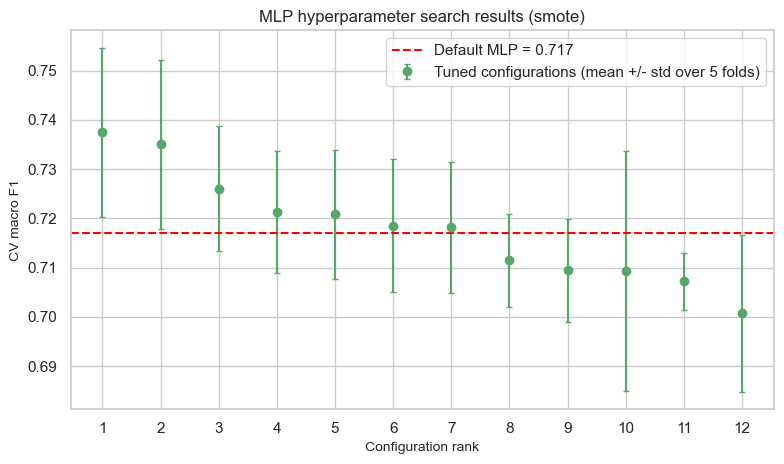

In [47]:
# figure 20: MLP search results, every configuration ranked by CV macro F1
res = pd.DataFrame(rs_mlp.cv_results_).sort_values('mean_test_score', ascending=False).reset_index(drop=True)
plt.figure(figsize=(8, 4.8))
plt.errorbar(res.index + 1, res.mean_test_score, yerr=res.std_test_score, fmt='o', color=COLORS['MLP'], capsize=2,
             label='Tuned configurations (mean +/- std over 5 folds)')
plt.axhline(default_mlp, color='red', linestyle='--', label=f'Default MLP = {default_mlp:.3f}')
plt.title(f'MLP hyperparameter search results ({mlp_strat})')
plt.xlabel('Configuration rank')
plt.ylabel('CV macro F1')
plt.xticks(res.index + 1)
plt.legend()
show('m20_mlp_tuning_results')

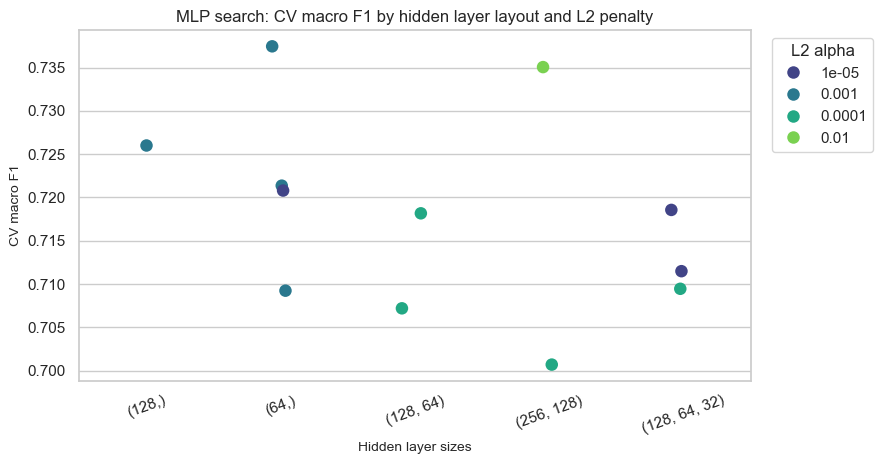

In [48]:
# figure 21: MLP architecture and regularisation against CV macro F1
res = pd.DataFrame(rs_mlp.cv_results_)
res['Hidden layers'] = res['param_clf__hidden_layer_sizes'].astype(str)
res['L2 alpha'] = res['param_clf__alpha'].astype(str)
order = sorted(res['Hidden layers'].unique(), key=lambda s: (s.count(',') + (0 if s.endswith(',)') else 1), s))
plt.figure(figsize=(9, 4.8))
sns.stripplot(data=res, x='Hidden layers', y='mean_test_score', hue='L2 alpha', order=order, size=9, palette='viridis')
plt.title('MLP search: CV macro F1 by hidden layer layout and L2 penalty')
plt.xlabel('Hidden layer sizes')
plt.ylabel('CV macro F1')
plt.xticks(rotation=20)
plt.legend(title='L2 alpha', bbox_to_anchor=(1.02, 1), loc='upper left')
show('m21_mlp_architecture_effect')

In [49]:
# test split evaluation of the tuned MLP (same metrics as the other two models)
mlp_best = searches['MLP'].best_estimator_
p_, pr_, m_ = evaluate(mlp_best)
evals['MLP'] = (p_, pr_)
pd.Series(m_).round(4)

accuracy         0.9247
balanced_acc     0.7247
macro_f1         0.7207
weighted_f1      0.9254
macro_roc_auc    0.9794
dtype: float64

In [50]:
# MLP classification report on the test split
print(classification_report(yte, evals['MLP'][0], target_names=classes, digits=3))

                               precision    recall  f1-score   support

       Crimes against Persons      0.537     0.489     0.512        45
  Crimes against Public Order      0.770     0.704     0.736       362
Fraud and White-Collar Crimes      0.891     0.875     0.883       271
                 Other Crimes      0.255     0.361     0.299        36
              Property Crimes      0.992     0.973     0.982      2332
               Violent Crimes      0.882     0.946     0.913       952

                     accuracy                          0.925      3998
                    macro avg      0.721     0.725     0.721      3998
                 weighted avg      0.927     0.925     0.925      3998



In [51]:
# comparison table: all tuned models on the test split
STRATEGY = dict(top2)
STRATEGY['MLP'] = mlp_strat
def metric_row(pred, proba):
    return {'accuracy': accuracy_score(yte, pred), 'balanced_acc': balanced_accuracy_score(yte, pred),
            'macro_f1': f1_score(yte, pred, average='macro'), 'weighted_f1': f1_score(yte, pred, average='weighted'),
            'macro_roc_auc': roc_auc_score(yte, proba, multi_class='ovr', average='macro')}
rows = []
for name in MODEL_ORDER:
    pred, proba = evals[name]
    rows.append({'model': name, 'imbalance': STRATEGY[name], 'cv_macro_f1': searches[name].best_score_,
                 **metric_row(pred, proba)})
compare = pd.DataFrame(rows)
compare['cv_test_gap'] = compare.cv_macro_f1 - compare.macro_f1
compare.round(4)

,model,imbalance,cv_macro_f1,accuracy,balanced_acc,macro_f1,weighted_f1,macro_roc_auc,cv_test_gap
0,XGBoost,class_weight,0.7797,0.9337,0.7632,0.7625,0.9340,0.9874,0.0172
1,HistGB,class_weight,0.7710,0.9312,0.7801,0.7679,0.9321,0.9833,0.0030
2,MLP,smote,0.7374,0.9247,0.7247,0.7207,0.9254,0.9794,0.0167


In [52]:
# per-class metrics for every model (long format) and macro F1 pivot
pc_rows = []
for name in MODEL_ORDER:
    pred, proba = evals[name]
    p, r, f, s = precision_recall_fscore_support(yte, pred)
    for i, cl in enumerate(classes):
        pc_rows.append({'model': name, 'class': cl, 'precision': p[i], 'recall': r[i], 'f1': f[i], 'support': s[i],
                        'roc_auc': roc_auc_score((yte == i).astype(int), proba[:, i])})
per_class_all = pd.DataFrame(pc_rows)
per_class_all.pivot(index='class', columns='model', values='f1')[MODEL_ORDER].round(3)

model,XGBoost,HistGB,MLP
class,,,
Crimes against Persons,0.652,0.646,0.512
Crimes against Public Order,0.784,0.777,0.736
Fraud and White-Collar Crimes,0.895,0.902,0.883
Other Crimes,0.343,0.389,0.299
Property Crimes,0.983,0.982,0.982
Violent Crimes,0.919,0.912,0.913


In [53]:
# training time and prediction time of each tuned model (refit with its selected parameters)
rows = []
for name in MODEL_ORDER:
    est = clone(searches[name].best_estimator_)
    t = time.time(); est.fit(Xtr, ytr); fit_s = time.time() - t
    t = time.time(); est.predict(Xte); pred_s = time.time() - t
    rows.append({'model': name, 'fit_time_s': fit_s, 'predict_time_s': pred_s,
                 'predict_ms_per_row': pred_s / len(Xte) * 1000})
timing = pd.DataFrame(rows)
timing.round(4)

,model,fit_time_s,predict_time_s,predict_ms_per_row
0,XGBoost,15.8106,0.5307,0.1327
1,HistGB,3.0966,0.2398,0.0600
2,MLP,11.4395,0.2726,0.0682


In [54]:
# bootstrap 95% confidence intervals for test macro F1 (same resamples for every model, 500 draws)
B = 500
rng = np.random.default_rng(SEED)
idx = rng.integers(0, len(yte), size=(B, len(yte)))
y_true = yte.values
boot = {name: np.array([f1_score(y_true[i], evals[name][0][i], average='macro') for i in idx]) for name in MODEL_ORDER}
ref = MODEL_ORDER[0]
rows = []
for name in MODEL_ORDER:
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    d = boot[name] - boot[ref]
    dlo, dhi = np.percentile(d, [2.5, 97.5])
    rows.append({'model': name, 'macro_f1_mean': boot[name].mean(), 'ci_low': lo, 'ci_high': hi,
                 f'diff_vs_{ref}': d.mean(), 'diff_ci_low': dlo, 'diff_ci_high': dhi,
                 f'share_better_than_{ref}': (d > 0).mean()})
boot_table = pd.DataFrame(rows)
boot_table.round(4)

,model,macro_f1_mean,ci_low,ci_high,diff_vs_XGBoost,diff_ci_low,diff_ci_high,share_better_than_XGBoost
0,XGBoost,0.7621,0.7297,0.7977,0.0000,0.0000,0.0000,0.000
1,HistGB,0.7674,0.7341,0.8011,0.0053,-0.0122,0.0231,0.708
2,MLP,0.7200,0.6848,0.7543,-0.0421,-0.0759,-0.0104,0.006


In [55]:
# agreement between models: pairwise identical predictions and error overlap
agree = pd.DataFrame(index=MODEL_ORDER, columns=MODEL_ORDER, dtype=float)
for a in MODEL_ORDER:
    for b in MODEL_ORDER:
        agree.loc[a, b] = (evals[a][0] == evals[b][0]).mean()
ok = {n: evals[n][0] == y_true for n in MODEL_ORDER}
rows = []
for b in MODEL_ORDER[1:]:
    a = MODEL_ORDER[0]
    rows.append({'pair': f'{a} vs {b}', 'both_correct': int((ok[a] & ok[b]).sum()),
                 f'only_{a}_correct': int((ok[a] & ~ok[b]).sum()), f'only_{b}_correct': int((~ok[a] & ok[b]).sum()),
                 'both_wrong': int((~ok[a] & ~ok[b]).sum())})
pd.DataFrame(rows)

,pair,both_correct,only_XGBoost_correct,only_HistGB_correct,both_wrong,only_MLP_correct
0,XGBoost vs HistGB,3688,45,35.0,230,NaN
1,XGBoost vs MLP,3625,108,NaN,193,72.0


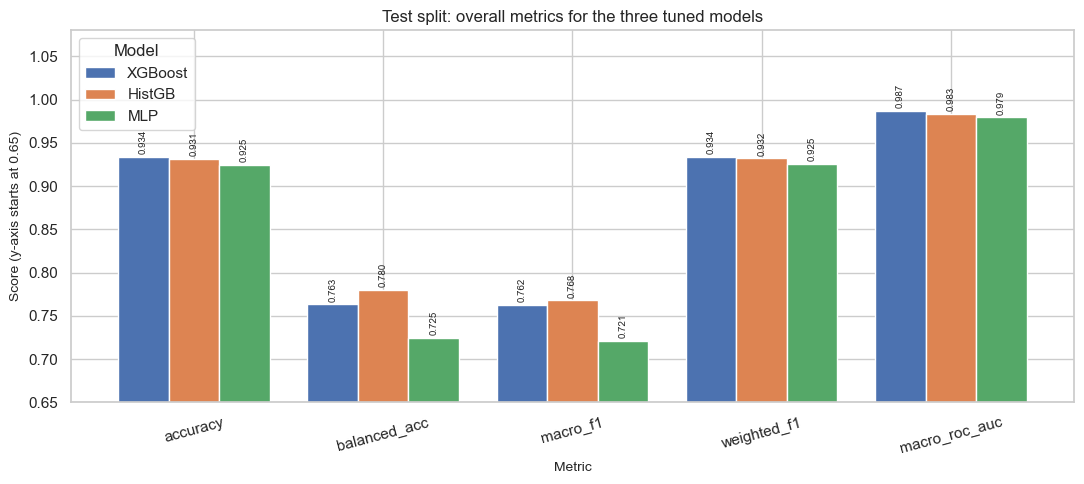

In [56]:
# figure 22: all tuned models on the test split, every overall metric
cmp_t = compare.set_index('model')[['accuracy', 'balanced_acc', 'macro_f1', 'weighted_f1', 'macro_roc_auc']].T[MODEL_ORDER]
ax = cmp_t.plot(kind='bar', figsize=(11, 5), color=[COLORS[m] for m in MODEL_ORDER], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=7, rotation=90, padding=2)
plt.title('Test split: overall metrics for the three tuned models')
plt.xlabel('Metric')
lo_y = max(0.0, math.floor((cmp_t.values.min() - 0.05) * 20) / 20)
plt.ylabel(f'Score (y-axis starts at {lo_y:.2f})')
plt.ylim(lo_y, 1.08)
plt.xticks(rotation=15)
plt.legend(title='Model', loc='upper left')
show('m22_comparison_overall_metrics')

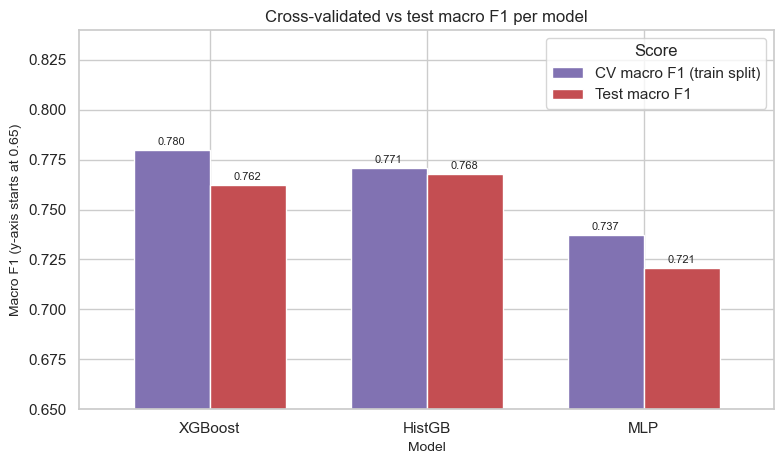

In [57]:
# figure 23: cross-validated against test macro F1 (generalisation gap)
g = compare.set_index('model')[['cv_macro_f1', 'macro_f1']].loc[MODEL_ORDER]
g.columns = ['CV macro F1 (train split)', 'Test macro F1']
ax = g.plot(kind='bar', figsize=(8, 4.8), color=['#8172b2', '#c44e52'], width=0.7)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8, padding=2)
plt.title('Cross-validated vs test macro F1 per model')
plt.xlabel('Model')
lo_y = max(0.0, math.floor((g.values.min() - 0.05) * 20) / 20)
plt.ylabel(f'Macro F1 (y-axis starts at {lo_y:.2f})')
plt.ylim(lo_y, min(1.0, g.values.max() + 0.06))
plt.xticks(rotation=0)
plt.legend(title='Score')
show('m23_cv_vs_test_gap')

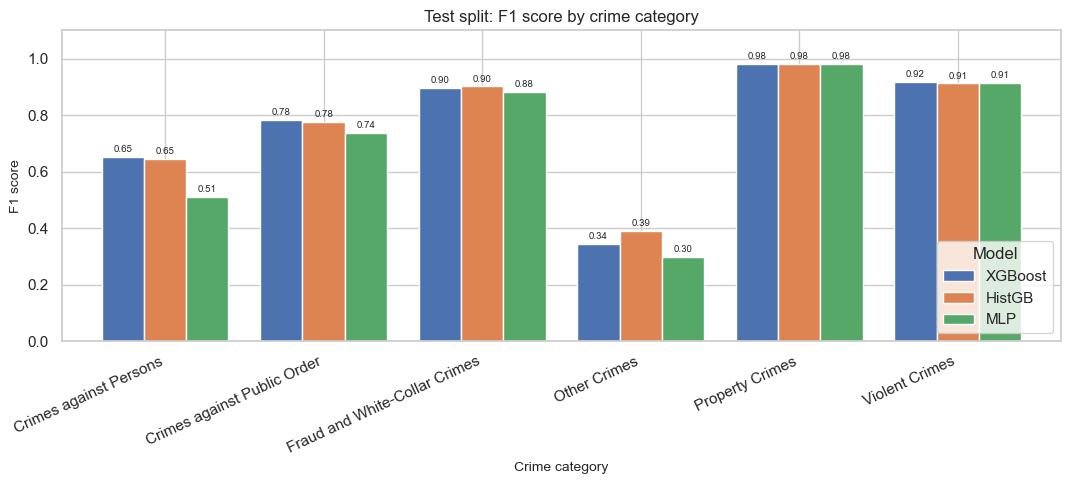

In [58]:
# figure 24: per-class F1 for every model
piv = per_class_all.pivot(index='class', columns='model', values='f1')[MODEL_ORDER]
ax = piv.plot(kind='bar', figsize=(11, 5), color=[COLORS[m] for m in MODEL_ORDER], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
plt.title('Test split: F1 score by crime category')
plt.xlabel('Crime category')
plt.ylabel('F1 score')
plt.ylim(0, 1.1)
plt.xticks(rotation=25, ha='right')
plt.legend(title='Model', loc='lower right')
show('m24_per_class_f1')

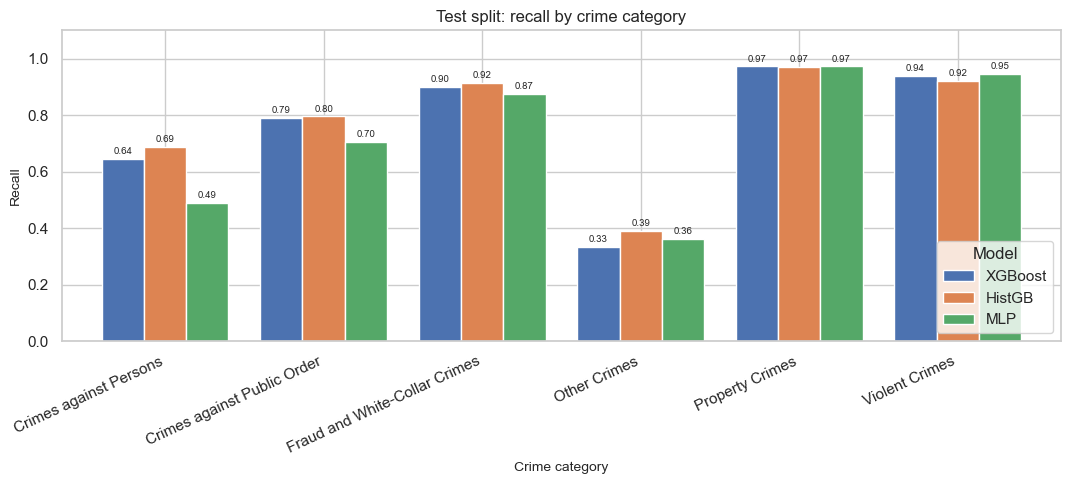

In [59]:
# figure 25: per-class recall for every model
piv = per_class_all.pivot(index='class', columns='model', values='recall')[MODEL_ORDER]
ax = piv.plot(kind='bar', figsize=(11, 5), color=[COLORS[m] for m in MODEL_ORDER], width=0.8)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', fontsize=7, padding=2)
plt.title('Test split: recall by crime category')
plt.xlabel('Crime category')
plt.ylabel('Recall')
plt.ylim(0, 1.1)
plt.xticks(rotation=25, ha='right')
plt.legend(title='Model', loc='lower right')
show('m25_per_class_recall')

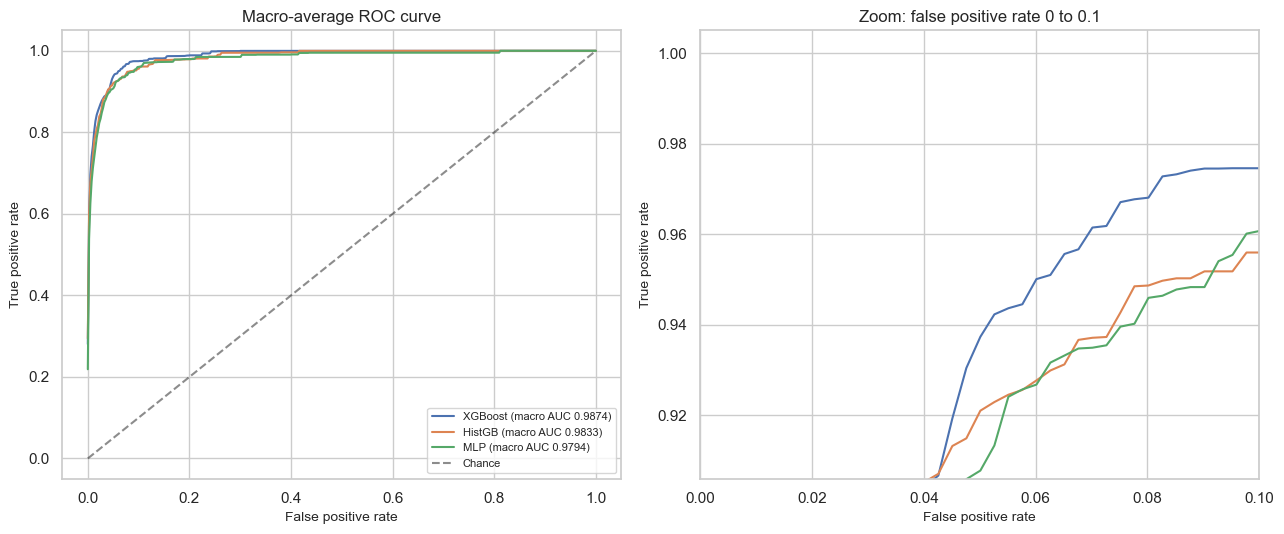

In [60]:
# figure 26: macro-averaged one-against-rest ROC curves (full view and zoomed view)
Yb = label_binarize(yte, classes=range(len(classes)))
grid = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
zoom_lo = 1.0
for name in MODEL_ORDER:
    proba = evals[name][1]
    tprs = [np.interp(grid, *roc_curve(Yb[:, i], proba[:, i])[:2]) for i in range(len(classes))]
    mean_tpr = np.mean(tprs, axis=0)
    zoom_lo = min(zoom_lo, np.interp(0.1, grid, mean_tpr))
    auc = compare.set_index('model').loc[name, 'macro_roc_auc']
    for ax in axes:
        ax.plot(grid, mean_tpr, color=COLORS[name], label=f'{name} (macro AUC {auc:.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Chance')
axes[0].set_title('Macro-average ROC curve')
axes[1].set_xlim(0, 0.1)
axes[1].set_ylim(max(0.0, zoom_lo - 0.05), 1.005)
axes[1].set_title('Zoom: false positive rate 0 to 0.1')
for ax in axes:
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate')
axes[0].legend(loc='lower right', fontsize=8)
show('m26_macro_roc_comparison')

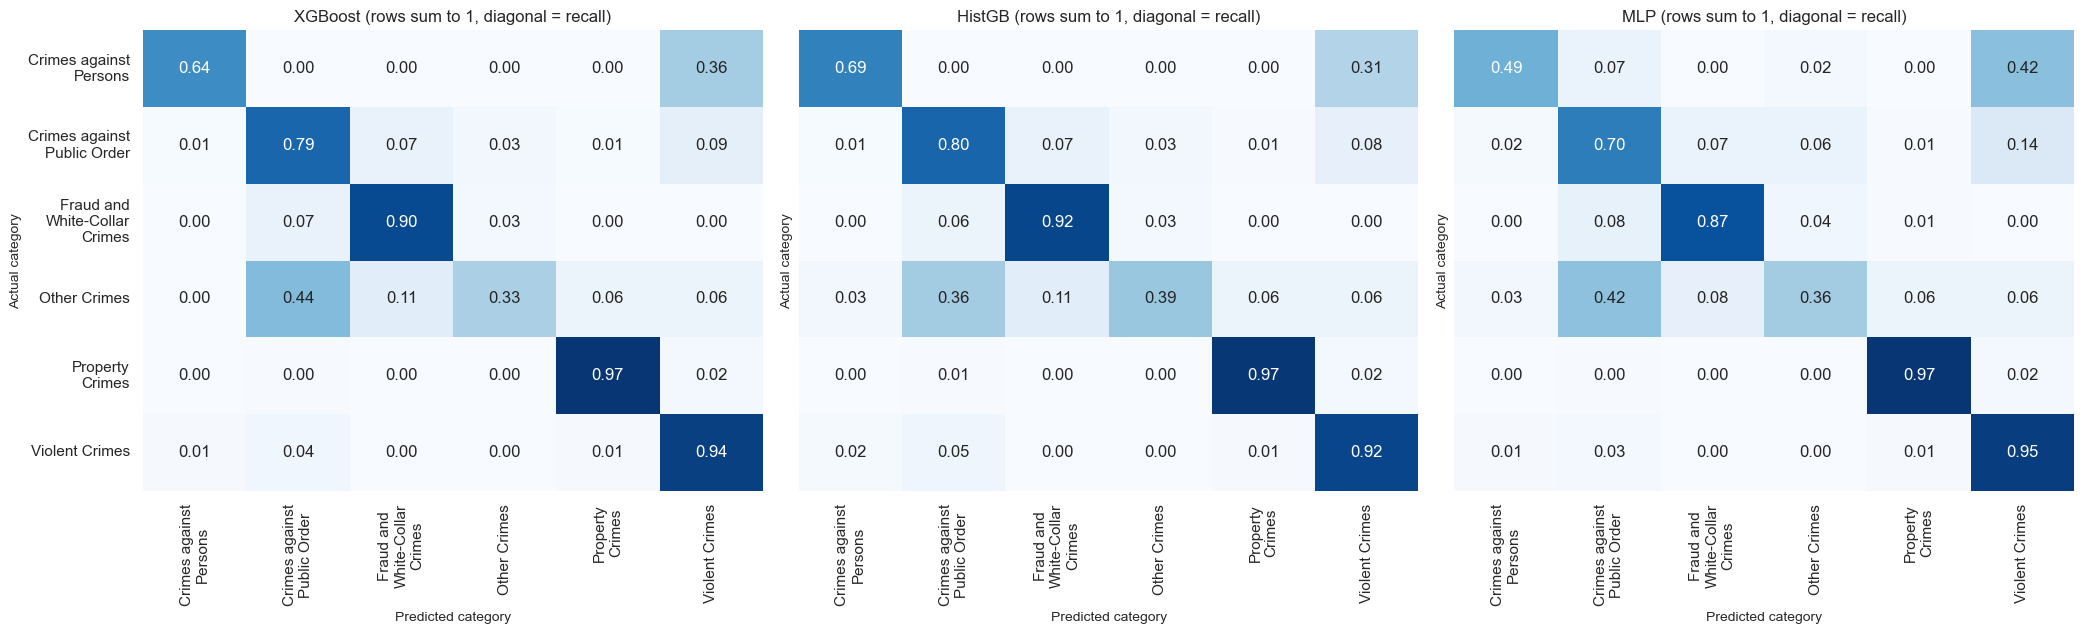

In [61]:
# figure 27: normalised confusion matrices side by side
fig, axes = plt.subplots(1, len(MODEL_ORDER), figsize=(7 * len(MODEL_ORDER), 6.5), sharey=True)
for ax, name in zip(axes, MODEL_ORDER):
    cmn = confusion_matrix(yte, evals[name][0], normalize='true')
    sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax,
                xticklabels=SHORT, yticklabels=SHORT)
    ax.set_title(f'{name} (rows sum to 1, diagonal = recall)')
    ax.set_xlabel('Predicted category')
    ax.set_ylabel('Actual category')
show('m27_confusion_matrices_comparison')

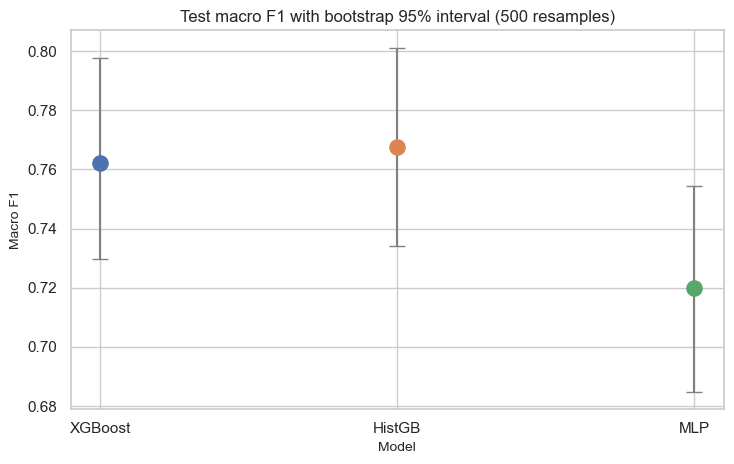

In [62]:
# figure 28: bootstrap 95% confidence interval of test macro F1
bt = boot_table.set_index('model').loc[MODEL_ORDER]
plt.figure(figsize=(7.5, 4.8))
plt.errorbar(range(len(bt)), bt.macro_f1_mean, yerr=[bt.macro_f1_mean - bt.ci_low, bt.ci_high - bt.macro_f1_mean],
             fmt='o', capsize=6, markersize=8, color='black', ecolor='gray')
for i, name in enumerate(MODEL_ORDER):
    plt.scatter(i, bt.macro_f1_mean[name], s=120, color=COLORS[name], zorder=3)
plt.xticks(range(len(bt)), MODEL_ORDER)
plt.title(f'Test macro F1 with bootstrap 95% interval ({B} resamples)')
plt.xlabel('Model')
plt.ylabel('Macro F1')
show('m28_bootstrap_macro_f1')

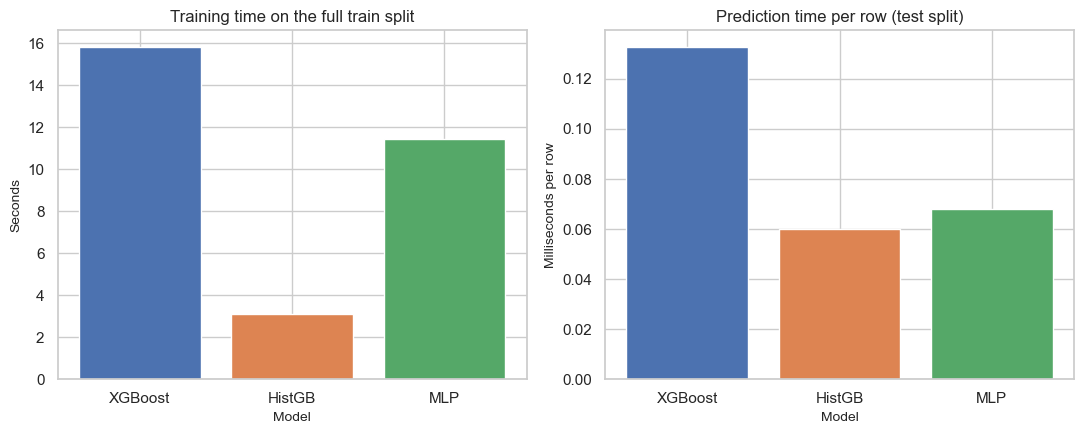

In [63]:
# figure 29: training and prediction time
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
tm = timing.set_index('model').loc[MODEL_ORDER]
axes[0].bar(tm.index, tm.fit_time_s, color=[COLORS[m] for m in tm.index])
axes[0].set_title('Training time on the full train split')
axes[0].set_xlabel('Model')
axes[0].set_ylabel('Seconds')
axes[1].bar(tm.index, tm.predict_ms_per_row, color=[COLORS[m] for m in tm.index])
axes[1].set_title('Prediction time per row (test split)')
axes[1].set_xlabel('Model')
axes[1].set_ylabel('Milliseconds per row')
show('m29_time_comparison')

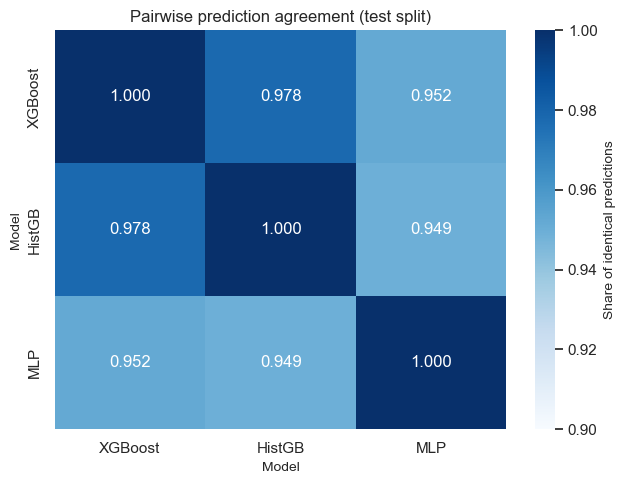

In [64]:
# figure 30: share of test rows on which two models predict the same category
plt.figure(figsize=(6.5, 5))
sns.heatmap(agree.astype(float), annot=True, fmt='.3f', cmap='Blues', vmin=0.9, vmax=1, cbar_kws={'label': 'Share of identical predictions'})
plt.title('Pairwise prediction agreement (test split)')
plt.xlabel('Model')
plt.ylabel('Model')
show('m30_prediction_agreement')

In [65]:
# final comparison table with the best value in each column marked, saved for the report
metric_cols = ['cv_macro_f1', 'accuracy', 'balanced_acc', 'macro_f1', 'weighted_f1', 'macro_roc_auc']
scorecard = compare.set_index('model')[['imbalance'] + metric_cols].join(timing.set_index('model')[['fit_time_s', 'predict_ms_per_row']])
scorecard.to_csv('model/model_comparison.csv')
per_class_all.to_csv('model/per_class_all_models.csv', index=False)
boot_table.to_csv('model/bootstrap_macro_f1.csv', index=False)
scorecard.round(4).style.highlight_max(subset=metric_cols, color='lightgreen').highlight_min(subset=['fit_time_s', 'predict_ms_per_row'], color='lightgreen')

,imbalance,cv_macro_f1,accuracy,balanced_acc,macro_f1,weighted_f1,macro_roc_auc,fit_time_s,predict_ms_per_row
model,,,,,,,,,
XGBoost,class_weight,0.779700,0.933700,0.763200,0.762500,0.934000,0.987400,15.810600,0.132700
HistGB,class_weight,0.771000,0.931200,0.780100,0.767900,0.932100,0.983300,3.096600,0.060000
MLP,smote,0.737400,0.924700,0.724700,0.720700,0.925400,0.979400,11.439500,0.068200


In [67]:
# save the tuned MLP pipeline and its selected parameters
import copy
os.makedirs('model', exist_ok=True)
# SMOTE is only used while fitting and holds a local function that cannot be pickled, so it is removed from the saved copy
mlp_to_save = copy.copy(mlp_best)
mlp_to_save.steps = [(n, 'passthrough' if n == 'sampler' else s) for n, s in mlp_best.steps]
joblib.dump(mlp_to_save, 'model/crime_pipeline_mlp.joblib')
assert (joblib.load('model/crime_pipeline_mlp.joblib').predict(Xte) == mlp_best.predict(Xte)).all()
with open('model/mlp_meta.json', 'w') as f:
    json.dump({'imbalance': mlp_strat, 'cv_macro_f1': float(rs_mlp.best_score_),
               'best_params': {k: (list(v) if isinstance(v, tuple) else v) for k, v in rs_mlp.best_params_.items()}}, f, indent=2)
print(sorted(os.listdir('model')))

['bootstrap_macro_f1.csv', 'crime_pipeline_final.joblib', 'crime_pipeline_mlp.joblib', 'meta.json', 'mlp_meta.json', 'mlp_selection.csv', 'model_comparison.csv', 'model_selection.csv', 'outlier_table.csv', 'per_class_all_models.csv', 'per_class_metrics.csv', 'test_predictions.csv', 'test_results.csv']
